<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/04.Implementing_A_GPT_Model_From_Scratch_To_Generate_Text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4 -- Implementing a GPT Model from Scratch to Generate Text

*Companion notebook untuk* Build a Large Language Model (From Scratch) *(Sebastian Raschka, Manning 2024)*
**Technical edition -- kode buku plus beberapa pengukuran tambahan**

Notebook ini berisi semua kode bab 4, dalam urutan buku. Di beberapa titik ada pengukuran tambahan yang tidak ada di buku, untuk menjawab pertanyaan "apa yang sebenarnya terjadi di sini?". Bagian-bagian itu disebut **Under the hood** dan boleh dilewati kalau hanya ingin mengikuti materi buku. Sel tambahan bisa dikenali dari komentar pembukanya, misalnya `# Under the hood`, `# Kalibrasi`, atau `# Pelengkapan`.

| Under the hood | Yang kita ukur | Hasil |
|---|---|---|
| 1. LayerNorm dan GELU | Kelas buatan buku dibandingkan dengan versi bawaan PyTorch, dan letak titik gradien nol GELU | Selisihnya hanya sebesar pembulatan float32; gradien GELU nol di x = -0.7525 |
| 2. Shortcut connection | Apakah efek shortcut bertahan di 100 seed dan di kedalaman 5, 10, dan 20 | Tanpa shortcut, gradien layer pertama di kedalaman 20 praktis nol; dengan shortcut gradien tetap hidup, tapi 25 dari 100 seed macet dengan gradien tepat nol; pada seed yang didiagnosis, penyebabnya GELU float32 yang jenuh |
| 3. Ukuran model | Apakah 621.83 MB sama dengan ukuran file model di disk | File-nya 669.89 MB; 48.00 MB di antaranya adalah 12 causal mask |
| 4. GPT tanpa training | Seberapa acak prediksi model yang belum dilatih | Sedikit lebih buruk dari tebakan acak yang merata (cross-entropy 11.20 vs ln V = 10.82); perbandingan CPU dan GPU dilewati karena run ini tanpa GPU |

Sampai bab 3 kita sudah punya dua bahan: pipeline yang mengubah teks menjadi token ID dan embedding (bab 2), dan multi-head attention yang membuat setiap token bisa melihat token-token sebelumnya (bab 3). Bab ini merakit keduanya menjadi model GPT utuh yang bisa menghasilkan teks. Supaya tidak kaget di akhir bab, hasilnya sebaiknya kita ketahui dari sekarang: diberi awal kalimat "Hello, I am", model kita akan melanjutkannya dengan "Featureiman Byeswickattribute argue". Itu bukan bug. Bobot model masih acak, dan melatihnya adalah pekerjaan bab 5. Yang kita bangun di sini adalah mesinnya.

Kalau dilihat dari dekat, mesin itu ternyata tidak serumit ukurannya. GPT hanya punya satu jenis block, yaitu *transformer block*, yang ditumpuk berkali-kali. Di dalamnya ada attention dari bab 3 dan tiga komponen kecil yang akan kita bangun satu per satu: layer normalization, feed forward network dengan aktivasi GELU, dan shortcut connection. Setiap komponen menyelesaikan masalah yang spesifik, dan masalah-masalah itu bisa kita lihat langsung dalam angka: aktivasi yang skalanya tidak terkendali, neuron yang berhenti belajar, dan gradien yang lenyap sebelum sampai ke layer awal.

Ada satu hal lain yang akan terus muncul sepanjang bab. Karena kode, seed, dan input-nya sama dengan buku, banyak output di sini bisa dicocokkan langsung dengan angka yang dicetak buku. Sebagian besar cocok sampai digit terakhir. Di beberapa tempat ada selisih kecil, dan selisih itu ternyata mengajarkan sesuatu tentang cara float32 menyimpan angka. Di tempat lain, gambar di buku memuat angka yang keliru, dan kita akan melacak dari mana angka itu berasal.

## Setup

Notebook ini cukup dijalankan dengan *Run all* dan tidak butuh GPU: semua listing bab 4 berjalan di CPU, seperti di buku. Yang perlu diperhatikan hanya RAM, karena Exercise 4.2 di akhir notebook membuat GPT-2 XL dengan bobot float32 sebesar 6,247.68 MB. Output yang tersimpan di sini berasal dari satu kali run di Google Colab dengan runtime CPU. Kode bab berasal dari repo resmi `rasbt/LLMs-from-scratch` (Apache-2.0) pada commit `cdbd33e`, dalam urutan buku. Dua sel contoh LayerNorm diambil dari versi repo saat buku dicetak, karena contoh itu belakangan diubah di repo; alasannya kita bahas di 4.2.

Sel pertama memeriksa empat paket yang dipakai notebook, yaitu `torch`, `tiktoken`, `matplotlib`, dan `numpy`, lalu hanya memasang yang belum ada, sebelum satu pun di-import. `importlib.util.find_spec` cukup memeriksa apakah sebuah paket bisa ditemukan, tanpa ikut memuatnya.

In [1]:

# Dependency -- pasang paket yang belum ada sebelum import apa pun
import importlib.util
import subprocess
import sys

required = ["torch", "tiktoken", "matplotlib", "numpy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("sudah ada        :", [pkg for pkg in required if pkg not in missing])
print("dipasang sekarang:", missing)


sudah ada        : ['torch', 'tiktoken', 'matplotlib', 'numpy']
dipasang sekarang: []


Keempat paket sudah tersedia di runtime Colab, jadi tidak ada yang dipasang. Sel berikutnya berasal dari repo resmi dan mencetak versi tiga paket utama.

In [2]:
from importlib.metadata import version

print("matplotlib version:", version("matplotlib"))
print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

matplotlib version: 3.10.0
torch version: 2.11.0+cpu
tiktoken version: 0.14.0


Run ini memakai torch 2.11.0, tiktoken 0.14.0, dan matplotlib 3.10.0. Akhiran `+cpu` pada versi torch menandakan build PyTorch tanpa dukungan CUDA, sesuai dengan runtime yang tidak punya GPU. Versi torch ini lebih baru daripada yang dipakai untuk output di repo resmi, baik notebook saat buku dicetak (torch 2.4.0) maupun versi terbarunya (torch 2.10.0).

Selisih versi seperti ini tidak memunculkan error di bab ini, karena kodenya hanya memakai bagian PyTorch yang sudah lama stabil: `nn.Embedding`, `nn.Linear`, `torch.tanh`, dan `register_buffer`. Yang bisa bergeser hanyalah digit terakhir hasil perhitungan float32 dan sedikit format cetak tensor. Pergeseran semacam itu kita bahas di tempat munculnya, mulai dari satu logit di 4.1.

In [3]:

import platform
import subprocess
import sys

import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

cpu_name = platform.processor() or "unknown"
if sys.platform == "darwin":
    cpu_name = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                              capture_output=True, text=True).stdout.strip()
HOST_DESC = f"{platform.platform()} ({cpu_name})"

print("python      :", platform.python_version())
print("host        :", HOST_DESC)
print("torch threads:", torch.get_num_threads())
print("device      :", device, "-> dipakai hanya di Under the hood 4; listing buku tetap di CPU")


python      : 3.13.16
host        : Linux-6.6.122+-x86_64-with-glibc2.39 (x86_64)
torch threads: 1
device      : cpu -> dipakai hanya di Under the hood 4; listing buku tetap di CPU


Run ini berjalan dengan Python 3.13.16 di Linux x86_64. Tidak ada GPU, jadi urutan prioritas di sel ini (`cuda`, lalu `mps`, lalu `cpu`) berakhir di `cpu`. Variabel `device` hanya dipakai di bagian akhir Under the hood 4, yang membandingkan CPU dengan akselerator. Listing buku sendiri sengaja tidak dipindah ke `device`. Tensor contohnya dibuat di CPU, sama seperti saat angka di buku dihasilkan, jadi keduanya bisa dibandingkan apa adanya.

Ada satu hal yang bisa mengganggu perbandingan itu. Beberapa sel menjalankan model dalam mode training, saat dropout aktif dan mengenolkan sebagian nilai secara acak, sehingga hasilnya bergantung pada pola acak dropout. Repo resmi mencatat bahwa dropout di CPU bisa menghasilkan pola yang berbeda antar sistem operasi (dengan rujukan ke PyTorch issue #121595), dan bahwa di Windows dan Linux output sel seperti itu bisa keluar berbeda dari buku. Run ini berjalan di Linux, jadi di 4.1 kita akan melihat apakah peringatan itu berlaku di sini.

## 4.1 Coding an LLM architecture

GPT menghasilkan teks satu token per langkah: ia membaca teks sejauh ini, menebak token berikutnya, menempelkannya, lalu mengulang. Karena arsitekturnya hanya tumpukan block yang sama, ukurannya bisa dinaikkan atau diturunkan lewat beberapa angka konfigurasi, dan kita bisa mulai dari ukuran terkecil. Buku memakai konfigurasi terkecil GPT-2 dari paper Radford dkk. (2019). Paper itu menyebut 117 juta parameter, angka yang belakangan dikoreksi menjadi 124 juta. Di 4.6 kita akan menghitung sendiri dari mana 124 juta itu datang, dan kenapa model yang kita bangun ternyata lebih besar dari itu.

"Parameter" di sini berarti bobot yang dilatih. Sebuah matriks bobot berukuran 2,048 x 2,048, misalnya, menyumbang 2,048 x 2,048 = 4,194,304 parameter, dan setiap elemennya diubah sendiri-sendiri oleh optimizer saat training untuk menurunkan loss.

Kenapa GPT-2 dan bukan GPT-3? Secara arsitektur keduanya hampir sama; GPT-3 hanya diskalakan dari 1.5 miliar ke 175 miliar parameter dan dilatih dengan data yang jauh lebih banyak. Bedanya, bobot GPT-2 dirilis terbuka dan modelnya muat di laptop. Sebagai gambaran skala, buku mengutip perkiraan Lambda Labs: melatih GPT-3 di satu GPU V100 akan butuh 355 tahun.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.1.png" width="700">

**Figure 4.1** Tiga tahap membangun LLM. Bab ini mengerjakan langkah 3 di tahap pertama, yaitu arsitektur LLM, sesudah pipeline data (bab 2) dan attention (bab 3). Training menyusul di bab 5.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.2.png" width="700">

**Figure 4.2** GPT dilihat dari atas: teks di-tokenize, diubah menjadi embedding, lalu melewati tumpukan transformer block yang masing-masing berisi masked multi-head attention dari bab 3. Tugas akhirnya menebak token berikutnya, misalnya "forward" sesudah "Every effort moves you".

Seluruh ukuran model ditentukan oleh beberapa angka saja, yang ditulis buku sebagai dictionary konfigurasi:

In [4]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

Setiap angka di dictionary ini punya peran yang jelas:

- `vocab_size` 50,257 adalah ukuran kosakata tokenizer BPE GPT-2 dari bab 2.
- `context_length` 1,024 adalah jumlah posisi yang dikenal positional embedding, sekaligus batas panjang input.
- `emb_dim` 768 adalah panjang vektor yang mewakili setiap token.
- `n_heads` 12 adalah jumlah head di multi-head attention bab 3; setiap head bekerja di 768 / 12 = 64 dimensi.
- `n_layers` 12 adalah jumlah transformer block yang ditumpuk.
- `drop_rate` 0.1 berarti 10% nilai di-nol-kan secara acak saat training, untuk mengurangi overfitting.
- `qkv_bias` False berarti layer `Linear` untuk query, key, dan value tidak memakai bias. Buku menyebut setting ini akan ditinjau lagi saat memuat bobot OpenAI "di bab 6"; pemuatan itu sebenarnya ada di bab 5 (kita catat sebagai Errata #5 di 4.6).

Dengan konfigurasi ini, buku membangun GPT dari luar ke dalam: kerangkanya dibuat dulu, lalu komponennya diisi satu per satu.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.3.png" width="700">

**Figure 4.3** Urutan pengerjaan bab ini: kerangka GPT dengan placeholder (1), layer normalization (2), GELU (3), feed forward (4), shortcut connection (5), digabung menjadi transformer block (6), lalu dirakit menjadi GPT final (7).

Listing 4.1 membuat kerangka itu. Transformer block dan layer normalization masih berupa kelas dummy yang mengembalikan input-nya apa adanya. Gunanya, alur data dari embedding ke block, ke normalisasi, lalu ke output head sudah bisa dijalankan dan diperiksa bentuknya sebelum komponen aslinya ada.

In [5]:
import torch
import torch.nn as nn


class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # Use a placeholder for TransformerBlock
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        # Use a placeholder for LayerNorm
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A simple placeholder

    def forward(self, x):
        # This block does nothing and just returns its input.
        return x


class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing and just returns its input.
        return x

Kerangka ini sudah memuat seluruh jalur GPT. Token ID diubah menjadi vektor oleh `tok_emb` (tabel 50,257 x 768), setiap posisi mendapat vektornya sendiri dari `pos_emb` (1,024 x 768), lalu keduanya dijumlahkan. Hasilnya melewati dropout, 12 `DummyTransformerBlock`, dan `DummyLayerNorm`, sebelum `out_head` memproyeksikan setiap vektor 768 dimensi kembali ke 50,257 skor, satu untuk setiap token di kosakata. Posisi dibuat dengan `torch.arange(seq_len, device=in_idx.device)`, jadi ia otomatis berada di device yang sama dengan input.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.4.png" width="700">

**Figure 4.4** Alur data dari ujung ke ujung: teks menjadi token ID, token ID menjadi embedding 768 dimensi, embedding melewati GPT, dan keluar satu vektor output untuk setiap token input. Dimensi output yang tertulis di callout gambar keliru (Errata #1, dibahas sesudah output di bawah). Karena jumlah output sama dengan jumlah input, token pertama ("Every") tidak pernah muncul sebagai tebakan; output terakhir adalah tebakan untuk token berikutnya.

Untuk mencobanya, buku memakai batch berisi dua kalimat pendek yang di-tokenize dengan `tiktoken`:

In [6]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


"Every effort moves you" menjadi `[6109, 3626, 6100, 345]` dan "Every day holds a" menjadi `[6109, 1110, 6622, 257]`. Kedua kalimat sengaja dipilih sama-sama 4 token, sehingga bisa langsung ditumpuk dengan `torch.stack` tanpa padding. Kolom pertamanya sama karena keduanya diawali "Every" (6109). Perhatikan juga bahwa 345 adalah " you" dan 257 adalah " a", lengkap dengan spasi di depannya: tokenizer GPT-2 menyimpan spasi sebagai bagian dari token kata sesudahnya.

Kalimat "Every effort moves you" akan menemani kita sampai 4.6. Sekarang batch ini kita masukkan ke kerangka GPT.

In [7]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)

logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


Output-nya berbentuk `[2, 4, 50257]`: 2 kalimat, 4 posisi, dan di setiap posisi satu skor untuk setiap token di kosakata. Skor mentah seperti ini disebut *logit*, dan di 4.7 kita akan mengubahnya menjadi token berikutnya. Untuk sekarang nilainya belum berarti apa-apa, karena semua bobot masih acak dan block-nya masih kosong.

Bentuk output ini sekaligus memperlihatkan kekeliruan pertama di buku, yang di notebook ini dicatat sebagai Errata #1. Callout di Figure 4.4 menyebut model mengembalikan satu vektor 768 dimensi untuk setiap token input, padahal output di atas berdimensi 50,257. Gambarnya sendiri ikut mengonfirmasi hal ini. Empat pasang angka "Outputs" di Figure 4.4 adalah dua kolom pertama logit kalimat pertama di atas, dipotong ke satu desimal: pasangan pertama, -1.2 dan 0.3, berasal dari -1.2034 dan 0.3201, dan ketiga pasangan lainnya cocok dengan cara yang sama. Jadi yang digambar memang logit 50,257 dimensi. Penulis mengakuinya sebagai salah ketik di gambar dalam GitHub Discussion #1065. Caption gambar yang sama juga menyebut `DummyGPTClass`, padahal nama kelas di listing adalah `DummyGPTModel`.

Sekarang soal peringatan dropout dari Setup. Model ini baru dibuat dan belum dipanggil `.eval()`, jadi forward di atas berjalan dalam mode training, dan angka persisnya bergantung pada pola acak dropout. Catatan repo memberi contoh baris pertama yang keluar di Windows dan Linux: `-0.9289, 0.2748, ...`. Run Linux ini justru mencetak `-1.2034, 0.3201, ...`, sama dengan buku. Issue PyTorch yang dirujuk repo mengaitkan perbedaan itu dengan dua jalur implementasi `bernoulli_`, fungsi yang mengundi nilai mana yang di-nol-kan dropout: satu memakai MKL (library matematika Intel) dan satu tidak. Jalur mana yang dipakai bergantung pada cara PyTorch di-build, jadi sistem operasi saja tidak menentukan pola acaknya.

Ada satu angka yang layak diperiksa lebih jauh: `1.6755` di baris pertama, posisi keempat, kolom kedua. Buku juga mencetak 1.6755 di situ, tapi output notebook repo resmi versi terbaru mencetak 1.6754. Kode, seed, dan input-nya sama. Bagaimana digit keempatnya bisa berbeda? Sel berikut mencetak nilai mentahnya.

In [8]:

# Kalibrasi -- nilai mentah logit yang tercetak 1.6754 di sini dan 1.6755 di buku
v = logits[0, 3, 1].item()
print(f"logits[0, 3, 1] = {v!r}")
print("float32 tetangga di atasnya:", repr(torch.nextafter(torch.tensor(v), torch.tensor(2.0)).item()))
print("dibulatkan 4 desimal        :", f"{v:.4f}")


logits[0, 3, 1] = 1.675450086593628
float32 tetangga di atasnya: 1.6754502058029175
dibulatkan 4 desimal        : 1.6755


Nilai mentahnya 1.675450086593628, hanya sekitar 8.7e-08 di atas 1.67545, yaitu batas antara dibulatkan ke 1.6754 atau ke 1.6755. Sekecil apa itu? Float32 tidak bisa menyimpan sembarang angka desimal; ia hanya punya titik-titik dengan jarak tertentu. Di rentang 1 sampai 2, jarak antara dua float32 yang bersebelahan adalah 2^-23, sekitar 1.19e-07, dan jarak ini disebut satu *ulp* (*unit in the last place*). Baris kedua output memperlihatkan float32 berikutnya di atas nilai kita, 1.6754502058029175, tepat satu ulp lebih tinggi. Satu ulp di bawah nilai kita ada 1.6754499673843384, yang sudah berada di bawah 1.67545 dan akan dicetak 1.6754.

Jadi selisih 8.7e-08 tadi kurang dari satu ulp. Angka 1.67545 sendiri tidak bisa disimpan di float32, dan tidak ada float32 lain di antara nilai kita dan batas pembulatan itu: elemen ini berada tepat di batas. Selisih satu ulp, yang bisa muncul hanya karena urutan penjumlahan di dalam perkalian matriks sedikit berbeda antar build PyTorch, sudah cukup untuk mengubah digit keempat yang tercetak. Run ini jatuh di sisi yang sama dengan buku, sedangkan output repo versi terbaru jatuh di sisi yang lain. Bobot dan arsitekturnya sama sekali tidak berbeda.

Komentar di baris pertama sel menulis bahwa logit ini tercetak 1.6754 "di sini" dan 1.6755 di buku. Komentar itu hanya berlaku untuk run yang jatuh di sisi lain batas, seperti output repo terbaru; untuk run ini, yang berlaku adalah output di bawahnya, 1.6755.

Pelajaran kecil ini berguna sepanjang bab. Kalau dua run berbeda di digit terakhir float32, itu belum tentu tanda ada yang salah. Pertanyaan yang tepat adalah apakah selisihnya lebih besar dari beberapa ulp.

## 4.2 Normalizing activations with layer normalization

Komponen pertama yang kita isi adalah layer normalization. Masalah yang diselesaikannya muncul di jaringan yang dalam. Saat training, sinyal gradien dirambatkan mundur dari output ke layer awal, dan di setiap layer ia bisa mengecil atau membesar. Kalau itu terjadi berulang kali di puluhan layer, gradien bisa menyusut hampir nol (*vanishing gradient*) atau justru meledak (*exploding gradient*), dan training menjadi lambat atau tidak stabil. Salah satu cara menjaganya adalah memastikan aktivasi yang masuk ke setiap layer punya skala yang wajar.

Itulah tugas layer normalization (LayerNorm). Untuk setiap contoh, ia menggeser dan menskalakan nilai-nilai di sepanjang dimensi fitur sehingga rata-ratanya 0 dan variansnya 1. Di GPT-2, LayerNorm dipasang di tiga tempat: sebelum multi-head attention, sebelum feed forward, dan sekali lagi sebelum output head.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.5.png" width="700">

**Figure 4.5** Enam aktivasi dari satu contoh dinormalisasi menjadi mean 0 dan varians 1. Gambar mencantumkan mean 0.13 dan varians 0.39 untuk enam aktivasi itu; angka varians itu keliru (Errata #2, diukur di bawah).

Supaya mekanismenya terlihat dengan angka kecil, buku memakai contoh mainan: dua contoh acak berdimensi 5 dilewatkan ke sebuah layer `Linear(5, 6)` yang diikuti ReLU.

In [9]:
torch.manual_seed(123)

# create 2 training examples with 5 dimensions (features) each
batch_example = torch.randn(2, 5)

layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


Perhatikan nol-nol di output ini: itu kerja ReLU, yang memotong setiap nilai negatif sebelum aktivasi menjadi 0, sehingga output layer ini tidak pernah negatif. Setiap baris adalah output untuk satu contoh input. (Buku menyebut baris kedua sebagai output "for the second row"; yang dimaksud adalah output untuk contoh input kedua.)

Sebelum menormalisasi, kita lihat dulu mean dan varians setiap baris.

In [10]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


Mean baris pertama 0.1324 dan baris kedua 0.2170; variansnya 0.0231 dan 0.0398. Argumen `keepdim=True` membuat hasilnya tetap berbentuk `[2, 1]`, bukan vektor `[2]`, sehingga nanti bisa langsung dikurangkan dari `out` yang berbentuk `[2, 6]` lewat broadcasting.

Ada satu detail yang akan muncul lagi. Secara bawaan, `Tensor.var` menghitung varians *unbiased*, yaitu jumlah kuadrat selisih dibagi n - 1 = 5, bukan dibagi n = 6. Kalau dibagi 6 (varians *biased*), varians baris pertama menjadi 0.0192, dihitung dari enam nilai `out` di atas. Angka ini lebih kecil dari 0.0231 karena pembaginya lebih besar.

Angka-angka ini sudah cukup untuk memeriksa Figure 4.5, dan di sinilah Errata #2. Enam aktivasi di gambar (0.22, 0.34, 0.00, 0.22, 0.00, 0.00) adalah baris pertama `out` yang dipotong ke dua desimal, dan mean 0.13 di gambar cocok dengan 0.1324 di atas. Tapi variansnya tertulis 0.39, sedangkan varians baris yang sama adalah 0.0231 (unbiased) atau 0.0192 (biased). Bahkan kalau dihitung dari enam angka dua desimal di gambar, varians unbiased-nya 0.111 / 5 = 0.0222. Tidak ada definisi varians yang menghasilkan 0.39 dari data itu. Hasil normalisasi di gambar (0.61, 1.41, -0.87, 0.58, -0.87, -0.87) juga cocok dengan sel sesudah ini, jadi yang keliru hanya label varians di gambar, bukan datanya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.6.png" width="700">

**Figure 4.6** Arah reduksi `dim`. `dim=0` menghitung ke bawah (satu nilai per kolom), sedangkan `dim=1` atau `dim=-1` menghitung ke samping (satu nilai per baris). Untuk tensor GPT berbentuk `[batch, tokens, emb]`, `dim=-1` tetap menunjuk dimensi embedding, jadi kode yang sama berlaku tanpa perlu diganti menjadi `dim=2`.

In [11]:
out_norm = (out - mean) / torch.sqrt(var)
print("Normalized layer outputs:\n", out_norm)

mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Hasil normalisasinya (`0.6159, 1.4126, -0.8719, ...`) kini memuat nilai negatif, karena setiap nilai diukur relatif terhadap rata-rata barisnya. Variansnya tercetak 1.0000, dan mean-nya hampir nol: 9.9341e-09 untuk baris pertama dan 1.9868e-08 untuk baris kedua.

Kenapa tidak tepat nol? Enam nilai yang secara matematis saling meniadakan dijumlahkan dalam float32, yang hanya menyimpan sekitar tujuh digit penting, dan yang tersisa adalah sisa pembulatan di digit kedelapan atau kesembilan. Sisa ini tidak harus sama antar run. Buku mencetak -5.9605e-08 untuk baris pertama, sedangkan run ini 9.9341e-09; baris kedua sama di keduanya. Angka buku itu pun bukan angka sembarang: -5.9605e-08 adalah tepat -2^-24, setengah ulp dari 1.0 di float32, jadi jelas merupakan jejak pembulatan di bit terakhir. Sama seperti kasus logit 1.6755 tadi, perbedaan ini hanya mencerminkan urutan operasi float32 yang sedikit berbeda.

Hal yang sama terlihat di format varians. Buku mencetaknya sebagai `tensor([[1.], [1.]])`, sedangkan di sini `1.0000`. PyTorch memakai format pendek `1.` hanya kalau semua elemen tensor tepat bilangan bulat. Format empat desimal di sini berarti setidaknya satu varians tidak tepat 1.0, melainkan meleset sangat sedikit, sementara di run buku keduanya keluar tepat 1.0.

Notasi ilmiah seperti `9.9341e-09` membuat angka sekecil itu terlihat penting, padahal tidak. Sel berikut mematikannya.

In [12]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Dengan `sci_mode=False`, PyTorch mencetak empat desimal biasa, sehingga sisa pembulatan tadi tampil sebagai `0.0000`. Pengaturan ini berlaku global: semua tensor yang dicetak di sisa notebook memakai notasi desimal. Kalau sisa pembulatannya negatif, tandanya tetap ikut tercetak sebagai `-0.0000`; kita akan bertemu bentuk itu sebentar lagi.

Langkah-langkah manual tadi sekarang dibungkus menjadi modul `LayerNorm` (listing 4.2). Ada dua detail di dalamnya. Pertama, `eps = 1e-5` ditambahkan ke varians sebelum diakarkan, supaya tidak terjadi pembagian dengan nol kalau semua nilai dalam satu baris sama. Kedua, varians dihitung dengan `unbiased=False`, yaitu dibagi n. Pilihan ini mengikuti GPT-2 asli, yang diimplementasikan di TensorFlow dengan varians biased, sehingga bobot pretrained yang dimuat nanti tetap cocok. Di dimensi embedding 768, bedanya dengan pembagi n - 1 sangat kecil; Under the hood 1 akan mengukurnya.

Modul ini juga punya dua parameter yang ikut dilatih, `scale` dan `shift`, dengan nilai awal 1 dan 0. Di awal training modul ini murni menormalisasi; kalau ternyata skala atau pergeseran lain lebih membantu, training bisa mengubah keduanya.

In [13]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

Sekarang modul ini kita coba, dan di sini ada satu keanehan kecil di buku. Cetakan buku menerapkan `LayerNorm(emb_dim=5)` ke `batch_example`, yaitu input mentah berdimensi 5, bukan ke `out`, output enam dimensi yang baru saja kita normalisasi dengan tangan. Dua sel berikut adalah versi itu, diambil dari repo resmi pada commit saat buku dicetak (`dc1b1a0`), persis seperti di buku.

In [14]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)

In [15]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Mean `-0.0000` dan `0.0000`, varians `1.0000` dan `1.0000`. Tanda minus di baris pertama adalah sisa pembulatan seperti tadi, kali ini bernilai negatif. Varians keluar 1.0000 karena varians asli setiap baris `batch_example`, yang diambil dari `randn`, jauh lebih besar dari `eps = 1e-5`, sehingga pengaruh `eps` tidak terlihat di empat desimal.

Contoh ini belakangan diperbaiki di repo. Pada 19 Februari 2026, PR #960 ("Use correct input in layernorm example") mengganti sel ini dengan `LayerNorm(emb_dim=6)` yang diterapkan ke `out`, yaitu aktivasi enam dimensi yang dinormalisasi dengan tangan di atas dan yang digambar di Figure 4.5. Dua sel berikut adalah versi terbaru itu. Hasilnya ternyata tidak lagi tepat 1.

In [16]:
ln = LayerNorm(emb_dim=6)
out_ln = ln(out)

In [17]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.9995],
        [0.9997]], grad_fn=<VarBackward0>)


Variansnya kini 0.9995 dan 0.9997, bukan 1.0000. Penyebabnya `eps`, dan kita bisa menghitungnya dengan tangan. Varians biased setiap baris `out` kecil: sekitar 0.0192 untuk baris pertama, seperti yang kita hitung tadi, dan sekitar 0.0332 untuk baris kedua, dihitung dengan cara yang sama dari enam nilai `out`. Karena `eps` ikut di dalam akar, varians output sesudah normalisasi menjadi var / (var + eps):

- baris 1: 0.0192 / (0.0192 + 0.00001) = 0.99948, tercetak `0.9995`
- baris 2: 0.0332 / (0.0332 + 0.00001) = 0.99970, tercetak `0.9997`

Makin kecil varians input, makin besar porsi `eps` di penyebut. Untuk aktivasi yang variansnya jauh di atas 1e-5, efek ini tidak terlihat; untuk input yang hampir konstan, justru `eps` yang mencegah pembagian dengan nol.

Kenapa normalisasinya dilakukan per contoh di sepanjang dimensi fitur, dan bukan per fitur di sepanjang batch seperti *batch normalization*? BatchNorm menghitung statistik dari seluruh batch, sehingga hasilnya bergantung pada isi dan ukuran batch. LayerNorm hanya melihat satu contoh, jadi hasilnya sama untuk batch berukuran 1 maupun 1,000. Sifat ini penting untuk LLM: saat menghasilkan teks, model sering bekerja dengan batch kecil, dan saat training terdistribusi, setiap device hanya memegang sebagian kecil batch.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.7.png" width="700">

**Figure 4.7** Progres sejauh ini: kerangka GPT (1) dan layer normalization (2) selesai. Berikutnya GELU (3) dan feed forward (4).

## 4.3 Implementing a feed forward network with GELU activations

Komponen berikutnya adalah jaringan kecil dua layer yang ada di setiap transformer block, dan yang menarik di sini adalah fungsi aktivasinya. Di contoh LayerNorm tadi kita memakai ReLU, yang memotong semua nilai negatif menjadi 0. LLM modern memakai aktivasi yang lebih mulus: GELU (*Gaussian error linear unit*) di GPT-2, dan SwiGLU (*Swish-gated linear unit*) di banyak model sesudahnya.

Definisi GELU yang eksak adalah $\mathrm{GELU}(x) = x \cdot \Phi(x)$, dengan $\Phi$ fungsi distribusi kumulatif normal standar. Cara membacanya: input dikalikan dengan peluang bahwa sebuah nilai acak dari distribusi normal standar lebih kecil dari input itu. Untuk x yang besar, peluang itu hampir 1 dan GELU hampir sama dengan x. Untuk x yang sangat negatif, peluangnya hampir 0 dan GELU hampir 0. Di antara keduanya, transisinya mulus. GPT-2 dilatih dengan aproksimasi yang lebih murah dihitung, yang ditemukan lewat *curve fitting*:

$$\mathrm{GELU}(x) \approx 0.5\,x\left(1 + \tanh\!\left[\sqrt{2/\pi}\,\left(x + 0.044715\,x^3\right)\right]\right)$$

Listing 4.3 menulis rumus aproksimasi itu sebagai modul, lalu sel sesudahnya menggambar GELU dan ReLU berdampingan.

In [18]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

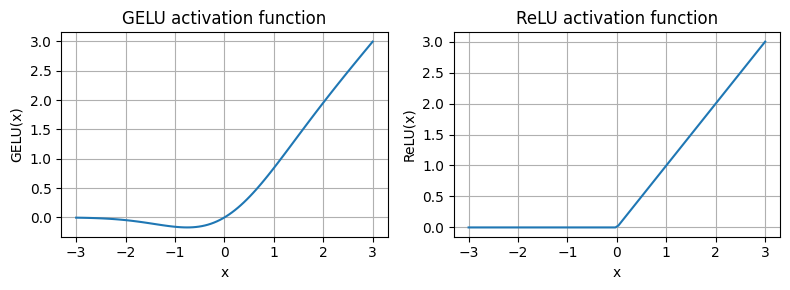

In [19]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

Plot di atas adalah Figure 4.8 buku, digambar langsung dari kode, jadi gambar 4.8 dari folder figure repo tidak ditampilkan lagi di notebook ini. ReLU (kanan) terdiri dari dua garis lurus: identitas untuk x > 0 dan nol untuk x < 0, dengan sudut tajam di 0. GELU (kiri) mulus di seluruh rentang, hampir sama dengan ReLU untuk |x| yang besar, tapi sedikit negatif di sisi kiri, dengan lembah dangkal di sekitar x = -0.75. Paragraf buku yang menjelaskan plot ini merujuk sudut tajam ReLU ke "(figure 4.18, right)"; Figure 4.18 adalah diagram generasi token di 4.7, jadi rujukan yang benar adalah Figure 4.8, panel kanan (Errata #3).

Bentuk lembah itu punya konsekuensi untuk training. Di ReLU, neuron yang pre-aktivasinya negatif menerima gradien tepat nol, sehingga bobot yang masuk ke neuron itu tidak diperbarui oleh contoh tersebut. Di GELU, gradien untuk input negatif tidak nol. Antara dasar lembah dan 0, kurvanya masih naik, jadi gradiennya positif. Di kiri lembah, kurvanya turun menuju dasar lembah, jadi gradiennya negatif: dari dasar lembah ke kiri, kemiringannya mula-mula makin curam, lalu makin landai dan mendekati nol. Secara matematis, satu-satunya titik dengan gradien tepat nol adalah dasar lembah itu sendiri, yang menurut buku ada di sekitar -0.75.

Sel berikut adalah Under the hood 1. Ia membandingkan `LayerNorm` dan `GELU` buatan buku dengan versi bawaan PyTorch (`nn.LayerNorm` dan `nn.GELU`), mengukur seberapa jauh aproksimasi tanh menyimpang dari GELU eksak (yang di PyTorch dihitung dengan fungsi `erf`), mencari letak tepat dasar lembah tadi, dan mengukur gradien GELU jauh di kiri, di x = -3. Dasar lembah dicari dengan *bisection*: rentang [-1, -0.5] dibelah dua berulang kali, dan setiap kali dipilih separuh yang masih memuat titik tempat turunan GELU berganti tanda. Sel ini menyimpan state generator acak di awal dan memulihkannya di akhir, jadi listing buku sesudahnya tetap mendapat angka acak yang sama.

In [20]:

# Under the hood 1 -- LayerNorm dan GELU versi buku vs implementasi bawaan PyTorch
rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser
torch.manual_seed(123)
x_probe = torch.randn(2, 4, 768)
ln_book, ln_torch = LayerNorm(768), nn.LayerNorm(768, eps=1e-5)
ln_diff = (ln_book(x_probe) - ln_torch(x_probe)).abs().max().item()
print(f"max |LayerNorm buku - nn.LayerNorm(768)|   : {ln_diff:.2e}")
for n in (5, 6, 768):
    print(f"rasio varians unbiased/biased, n = {n:>3}      : {n / (n - 1):.4f}")

xs = torch.linspace(-3, 3, 100_001, dtype=torch.float64)
gelu_err = (GELU()(xs) - nn.GELU()(xs)).abs()
print(f"max |GELU tanh (buku) - GELU erf| di [-3,3] : {gelu_err.max().item():.2e} pada x = {xs[gelu_err.argmax()].item():.3f}")
tanh_diff = (GELU()(xs.float()) - nn.GELU(approximate="tanh")(xs.float())).abs().max().item()
print(f"max |GELU buku - nn.GELU('tanh')| float32  : {tanh_diff:.2e}")


def gelu_zero_grad(fn, lo=-1.0, hi=-0.5, iters=60):
    # bisection pada turunan (autograd): turunan < 0 berarti titik minimum ada di kanan
    lo = torch.tensor(lo, dtype=torch.float64)
    hi = torch.tensor(hi, dtype=torch.float64)
    for _ in range(iters):
        mid = ((lo + hi) / 2).requires_grad_(True)
        fn(mid).backward()
        if mid.grad < 0:
            lo = mid.detach()
        else:
            hi = mid.detach()
    return mid.detach()


x0_values = {}
for name, fn in [("tanh", GELU()), ("erf", nn.GELU())]:
    x0 = gelu_zero_grad(fn)
    x_neg3 = torch.tensor(-3.0, dtype=torch.float64, requires_grad=True)
    fn(x_neg3).backward()
    x0_values[name] = x0.item()
    print(f"GELU {name:>4}: turunan = 0 di x = {x0.item():.4f}, GELU(x) = {fn(x0).item():.4f}, "
          f"turunan di x = -3: {x_neg3.grad.item():.4f}")
torch.set_rng_state(rng_state)


max |LayerNorm buku - nn.LayerNorm(768)|   : 2.38e-07
rasio varians unbiased/biased, n =   5      : 1.2500
rasio varians unbiased/biased, n =   6      : 1.2000
rasio varians unbiased/biased, n = 768      : 1.0013
max |GELU tanh (buku) - GELU erf| di [-3,3] : 4.73e-04 pada x = 2.699
max |GELU buku - nn.GELU('tanh')| float32  : 2.38e-07
GELU tanh: turunan = 0 di x = -0.7525, GELU(x) = -0.1700, turunan di x = -3: -0.0116
GELU  erf: turunan = 0 di x = -0.7518, GELU(x) = -0.1700, turunan di x = -3: -0.0119


Output Under the hood 1 kita baca sambil menjawab tiga pertanyaan, mulai dari yang paling dasar: apakah kelas buatan buku benar? `LayerNorm` buku dan `nn.LayerNorm(768)` berbeda paling jauh 2.38e-07, seukuran satu atau dua ulp float32 untuk nilai berorde 1. Rumusnya sama persis: varians biased, `eps` di dalam akar, serta `scale` dan `shift` yang dimulai dari 1 dan 0. Kelas `GELU` buku juga sama dengan `nn.GELU(approximate="tanh")`, dengan selisih paling jauh 2.38e-07.

Lalu, seberapa penting pilihan pembagi varians? Rasio varians unbiased terhadap biased adalah n / (n - 1): 1.2500 untuk n = 5, 1.2000 untuk n = 6, dan 1.0013 untuk n = 768. Buku menyebut pilihan ini tidak berarti untuk LLM, dan di dimensi 768 itu benar, karena selisihnya hanya 0.13%. Di contoh mainan berdimensi 5 atau 6, selisihnya 20 sampai 25%, cukup besar untuk terlihat jelas di angka yang tercetak, seperti 0.0231 dan 0.0192 tadi.

Terakhir, seberapa baik aproksimasi tanh, dan di mana gradien GELU nol? Di rentang [-3, 3], aproksimasi tanh paling jauh meleset 4.73e-04 dari GELU eksak, di x = 2.699 (selisih kedua rumus simetris, jadi angka yang sama juga muncul di -2.699). Selisih sebesar itu kecil dibanding aktivasi yang berorde 1: di x = 2.699, GELU sendiri sekitar 2.69, jadi selisihnya kurang dari 0.02%. Untuk keperluan bab ini, kedua rumus praktis sama.

Dasar lembahnya ada di x = -0.7525 untuk versi tanh dan -0.7518 untuk versi eksak, dengan nilai GELU -0.1700 di keduanya, jadi "sekitar -0.75" di buku tepat. Yang lebih penting untuk training adalah sisi kiri lembah: di x = -3, turunan GELU masih -0.0116 (versi tanh) dan -0.0119 (versi eksak), kecil tapi bukan nol, sedangkan turunan ReLU di sana tepat 0.

Jadi kelas buatan sendiri di bab ini bisa diganti `nn.LayerNorm` dan `nn.GELU(approximate="tanh")` tanpa mengubah output secara berarti, dan versi bawaan PyTorch memakai kernel yang sudah dioptimasi. Notebook ini tetap memakai kelas buku supaya setiap rumusnya terlihat.

Setelah GELU siap, feed forward network (listing 4.4) tinggal disusun: `Linear(768 -> 3072)`, GELU, lalu `Linear(3072 -> 768)`. Lebar layer tengah, 4 x `emb_dim`, adalah konvensi GPT-2. Sel repo sesudahnya hanya mencetak `emb_dim` dari konfigurasi.

In [21]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

In [22]:
print(GPT_CONFIG_124M["emb_dim"])

768


Dengan `emb_dim` = 768, layer pertama `FeedForward` melebar ke 4 x 768 = 3,072 unit.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.9.png" width="700">

**Figure 4.9** Bentuk tensor di dalam feed forward network untuk input `(2, 3, 768)`: layer pertama menghasilkan `(2, 3, 3072)`, GELU tidak mengubah bentuk, dan layer kedua mengembalikannya ke `(2, 3, 768)`. Ukuran batch dan jumlah token bebas; hanya dimensi embedding yang dikunci oleh ukuran bobot.

Kita uji dengan input acak berbentuk `[2, 3, 768]`: 2 contoh, masing-masing 3 token.

In [23]:
ffn = FeedForward(GPT_CONFIG_124M)

# input shape: [batch_size, num_token, emb_size]
x = torch.rand(2, 3, 768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


Output-nya `torch.Size([2, 3, 768])`, sama persis dengan bentuk input. Kesamaan bentuk inilah yang nanti membuat block bisa ditumpuk tanpa adaptor di antaranya. Di dalamnya, setiap token sempat diproyeksikan ke ruang 3,072 dimensi, dilewatkan ke GELU, lalu dipadatkan kembali ke 768 dimensi. Ruang yang lebih lebar itu memberi model tempat untuk membentuk kombinasi fitur yang lebih kaya sebelum diringkas lagi.

Satu hal membedakan feed forward dari attention: ia bekerja per posisi. Setiap token diolah sendiri-sendiri dengan bobot yang sama, tanpa melihat token lain. Pertukaran informasi antartoken hanya terjadi di attention.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.10.png" width="700">

**Figure 4.10** Ekspansi dan kontraksi di feed forward: 768 nilai menjadi 3,072, lalu kembali menjadi 768.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.11.png" width="700">

**Figure 4.11** Progres: layer normalization, GELU, dan feed forward (2 sampai 4) selesai. Berikutnya shortcut connection.

## 4.4 Adding shortcut connections

Di awal 4.2 kita menyebut vanishing gradient sebagai masalah jaringan yang dalam. LayerNorm menjaga skala aktivasi; shortcut connection mengatasi masalah yang sama dari sisi gradien. Idenya berasal dari ResNet di computer vision, dan bentuknya sangat sederhana: output sebuah layer dijumlahkan dengan input-nya sendiri. Shortcut ini juga disebut *skip connection* atau *residual connection*.

Kenapa penjumlahan sesederhana itu membantu? Saat backpropagation, gradien yang dirambatkan mundur dikalikan dengan turunan setiap layer yang dilewatinya. Kalau faktor-faktor itu kecil, hasil kalinya menyusut eksponensial seiring kedalaman, dan layer-layer awal hampir tidak belajar. Dengan shortcut, turunan `x + layer(x)` selalu memuat suku identitas, sehingga gradien punya jalur untuk melompati layer tanpa ikut dikalikan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.12.png" width="700">

**Figure 4.12** Jaringan lima layer tanpa shortcut (kiri) dan dengan shortcut (kanan). Angka di samping setiap layer adalah rata-rata nilai absolut gradien bobotnya: di kiri menyusut sampai 0.0002 dan 0.0001 di layer awal; di kanan, empat layer pertama bertahan di 0.20 sampai 0.32, dan layer terakhir 1.32.

Listing 4.5 membangun jaringan itu. Fungsi `print_gradients` menjalankan satu forward pass, menghitung loss MSE terhadap target 0, menjalankan backward, lalu mencetak rata-rata nilai absolut gradien setiap matriks bobot.

In [24]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            # Compute the output of the current layer
            layer_output = layer(x)
            # Check if shortcut can be applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x


def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target
    # and output are
    loss = nn.MSELoss()
    loss = loss(output, target)

    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

Shortcut hanya ditambahkan kalau bentuk input dan output layer sama (`x.shape == layer_output.shape`). Dengan `layer_sizes = [3, 3, 3, 3, 3, 1]`, empat layer pertama memetakan 3 nilai ke 3 nilai dan mendapat shortcut, sedangkan layer terakhir memetakan 3 ke 1 dan tidak. Kita mulai dari jaringan tanpa shortcut.

In [25]:
layer_sizes = [3, 3, 3, 3, 3, 1]

sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173584925942123
layers.1.0.weight has gradient mean of 0.00012011159560643137
layers.2.0.weight has gradient mean of 0.0007152040489017963
layers.3.0.weight has gradient mean of 0.0013988736318424344
layers.4.0.weight has gradient mean of 0.005049645435065031


Gradien menyusut dari 0.00505 di layer terakhir (`layers.4`) ke 0.00020 di layer pertama (`layers.0`), dengan titik terendah 0.00012 di `layers.1`. Layer pertama hanya menerima sekitar 1/25 gradien layer terakhir, padahal jaringan ini cuma lima layer. Sekarang jaringan yang sama, dengan seed yang sama, tapi memakai shortcut.

In [26]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896995544433594
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258540630340576


Dengan shortcut, gradien layer pertama naik dari 0.00020 menjadi 0.2217, sekitar 1,100 kali lebih besar. Empat layer yang punya shortcut kini berada di kisaran 0.21 sampai 0.33, dan hanya `layers.4`, yang tidak punya shortcut, mencapai 1.3259. Polanya sama dengan Figure 4.12.

Kalau dibandingkan dengan buku, delapan dari sepuluh gradien ini cocok sampai enam atau tujuh digit penting lalu mulai berbeda, dan dua sisanya sama persis. Apakah selisih di digit belakang itu berarti ada yang salah? Sel berikut membandingkan kesepuluh angka itu dengan nilai di buku dan dengan output notebook repo resmi versi terbaru, dalam satuan ulp float32 seperti yang kita kenal di 4.1.

In [27]:

# Kalibrasi -- gradien listing 4.5 di mesin ini vs buku vs output repo HEAD (ch04.ipynb @ cdbd33e)
import numpy as np

book_values = {
    False: [0.00020173587836325169, 0.0001201116101583466, 0.0007152041653171182,
            0.001398873864673078, 0.005049646366387606],
    True: [0.22169792652130127, 0.20694105327129364, 0.32896995544433594,
           0.2665732502937317, 1.3258541822433472],
}
repo_values = {
    False: [0.00020173587836325169, 0.00012011159560643137, 0.0007152039906941354,
            0.0013988736318424344, 0.005049645435065031],
    True: [0.22169792652130127, 0.20694106817245483, 0.32896995544433594,
           0.2665732204914093, 1.3258540630340576],
}
ulp_vs_book, ulp_vs_repo = [], []
for use_shortcut, net in [(False, model_without_shortcut), (True, model_with_shortcut)]:
    ours = [p.grad.abs().mean().item() for n, p in net.named_parameters() if "weight" in n]
    for i, (a, b, r) in enumerate(zip(ours, book_values[use_shortcut], repo_values[use_shortcut])):
        ulp = float(np.spacing(np.float32(b)))
        ulp_vs_book.append(round(abs(a - b) / ulp))
        ulp_vs_repo.append(round(abs(a - r) / ulp))
        print(f"shortcut={use_shortcut!s:5} layers.{i}: {a:.9e} | buku {abs(a - b) / ulp:3.0f} ulp | "
              f"repo {abs(a - r) / ulp:3.0f} ulp")


shortcut=False layers.0: 2.017358493e-04 | buku   2 ulp | repo   2 ulp
shortcut=False layers.1: 1.201115956e-04 | buku   2 ulp | repo   0 ulp
shortcut=False layers.2: 7.152040489e-04 | buku   2 ulp | repo   1 ulp
shortcut=False layers.3: 1.398873632e-03 | buku   2 ulp | repo   0 ulp
shortcut=False layers.4: 5.049645435e-03 | buku   2 ulp | repo   0 ulp
shortcut=True  layers.0: 2.216979116e-01 | buku   1 ulp | repo   1 ulp
shortcut=True  layers.1: 2.069410533e-01 | buku   0 ulp | repo   1 ulp
shortcut=True  layers.2: 3.289699554e-01 | buku   0 ulp | repo   0 ulp
shortcut=True  layers.3: 2.665732205e-01 | buku   1 ulp | repo   0 ulp
shortcut=True  layers.4: 1.325854063e+00 | buku   1 ulp | repo   0 ulp


Tidak ada yang berbeda lebih dari 2 ulp. Terhadap buku, 2 dari 10 nilai sama sampai bit terakhir dan sisanya berbeda 1 atau 2 ulp; terhadap output repo versi terbaru, 6 nilai sama dan sisanya juga berbeda 1 atau 2 ulp. Untuk gradien di sekitar 2e-4, satu ulp adalah 2^-36, sekitar 1.5e-11.

Lalu kenapa masih ada selisih, walaupun sekecil itu? Ketiga run (buku, repo, dan run ini) memakai build PyTorch yang berbeda, dan run ini berjalan di CPU x86_64. Di dalam `Linear` dan `mean`, banyak bilangan dijumlahkan, dan urutan penjumlahannya bisa berbeda antar build atau arsitektur CPU. Penjumlahan float32 tidak sepenuhnya asosiatif: (a + b) + c tidak selalu sama persis dengan a + (b + c) di bit terakhirnya. Float32 menyimpan sekitar tujuh digit penting, jadi dari 17 digit yang dicetak `print_gradients`, digit sesudah yang ketujuh atau kedelapan hanyalah sisa representasi. Pada presisi yang bermakna, ketiga run sama.

Tapi satu jaringan dengan satu seed belum cukup untuk menyimpulkan bahwa shortcut selalu menyelamatkan gradien. Under the hood 2 mengulang percobaan ini di 100 seed dan tiga kedalaman: 5, 10, dan 20 layer. Jaringannya memakai `forward` yang sama persis dengan listing 4.5; hanya jumlah layernya yang bisa diatur. Untuk setiap kombinasi, sel ini mencetak median gradien layer pertama dan median rasio gradien layer pertama terhadap layer terakhir. Rasio ini mengukur langsung seberapa jauh gradien meluruh dari ujung ke pangkal jaringan.

Seed yang gradien layer terakhirnya tepat nol dihitung terpisah, karena rasionya tidak terdefinisi. Seed seperti itu ternyata muncul di jaringan yang dalam, dan untuk salah satunya sel ini juga menelusuri apa yang terjadi di dalam jaringan.

In [28]:

# Under the hood 2 -- apakah efek shortcut bertahan lintas seed dan kedalaman?
import statistics

rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser


class DeepExampleNetwork(ExampleDeepNeuralNetwork):
    # forward() diwarisi verbatim dari listing 4.5; hanya jumlah layer yang fleksibel
    def __init__(self, layer_sizes, use_shortcut):
        nn.Module.__init__(self)
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[i], layer_sizes[i + 1]), GELU())
            for i in range(len(layer_sizes) - 1)
        ])


def weight_grad_means(net, x):
    loss = nn.MSELoss()(net(x), torch.tensor([[0.]]))
    loss.backward()
    return [p.grad.abs().mean().item() for n, p in net.named_parameters() if "weight" in n]


uth2, first_grads, degenerate_seeds = {}, {}, {}
print(f"{'depth':>5} {'shortcut':>8} {'degenerate':>10} {'median |g| layer pertama':>25} {'median rasio pertama/terakhir':>30}")
for depth in (5, 10, 20):
    for use_shortcut in (False, True):
        firsts, ratios, degenerate = {}, [], []
        for seed in range(100):
            torch.manual_seed(seed)
            net = DeepExampleNetwork([3] * depth + [1], use_shortcut)
            g = weight_grad_means(net, sample_input)
            if g[-1] == 0.0:          # loss tepat 0 -> semua gradien 0
                degenerate.append(seed)
                continue
            firsts[seed] = g[0]
            ratios.append(g[0] / g[-1])
        first_grads[(depth, use_shortcut)] = firsts
        degenerate_seeds[(depth, use_shortcut)] = degenerate
        uth2[(depth, use_shortcut)] = (len(degenerate), statistics.median(firsts.values()), statistics.median(ratios))
        print(f"{depth:>5} {str(use_shortcut):>8} {len(degenerate):>10} "
              f"{statistics.median(firsts.values()):>25.3e} {statistics.median(ratios):>30.3e}")

pairs = [s for s in range(100) if s in first_grads[(5, False)] and s in first_grads[(5, True)]]
wins5 = sum(first_grads[(5, True)][s] > first_grads[(5, False)][s] for s in pairs)
print(f"\ndepth 5 (konfigurasi buku): shortcut memberi gradien layer pertama lebih besar di {wins5}/{len(pairs)} seed")

seed_d = degenerate_seeds[(20, True)][0]
torch.manual_seed(seed_d)
net = DeepExampleNetwork([3] * 20 + [1], use_shortcut=True)
h = sample_input
for layer in net.layers[:-1]:
    h = h + layer(h)
pre_act = net.layers[-1][0](h)
print(f"diagnosis seed {seed_d} (depth 20, shortcut): max |residual| sebelum layer terakhir = {h.abs().max().item():.2f}, "
      f"pre-aktivasi terakhir = {pre_act.item():.2f}")
gelu_pre = {"tanh float32": GELU()(pre_act).item(), "erf float32": nn.GELU()(pre_act).item(),
            "erf float64": nn.GELU()(pre_act.double()).item()}
print("  " + " | ".join(f"GELU {k}(pre) = {v!r}" for k, v in gelu_pre.items()))
gelu64_as_f32 = torch.tensor(gelu_pre["erf float64"], dtype=torch.float32).item()
print(f"  nilai float64 itu disimpan sebagai float32: {gelu64_as_f32!r} (nol: {gelu64_as_f32 == 0.0})")
torch.set_rng_state(rng_state)


depth shortcut degenerate  median |g| layer pertama  median rasio pertama/terakhir
    5    False          0                 1.073e-04                      1.073e-02
    5     True          0                 7.145e-03                      1.410e-01
   10    False          0                 1.591e-07                      9.297e-06
   10     True          3                 5.979e-03                      8.626e-02
   20    False          0                 1.240e-13                      1.157e-11
   20     True         25                 1.697e+00                      8.560e-02

depth 5 (konfigurasi buku): shortcut memberi gradien layer pertama lebih besar di 98/100 seed
diagnosis seed 6 (depth 20, shortcut): max |residual| sebelum layer terakhir = 37.60, pre-aktivasi terakhir = -7.31
  GELU tanh float32(pre) = -0.0 | GELU erf float32(pre) = -0.0 | GELU erf float64(pre) = -9.675597467021337e-13
  nilai float64 itu disimpan sebagai float32: -9.67559799641693e-13 (nol: False)


Mulai dari kedalaman yang dipakai buku. Di kedalaman 5, shortcut memberi gradien layer pertama yang lebih besar di 98 dari 100 seed, dan median rasio pertama/terakhir naik dari 1.07e-02 menjadi 1.41e-01. Jadi hasil buku bukan kebetulan seed 123.

Sekarang jaringannya diperdalam. Tanpa shortcut, median rasio itu jatuh dari 1.07e-02 di kedalaman 5 ke 9.30e-06 di kedalaman 10, lalu ke 1.16e-11 di kedalaman 20. Setiap tambahan lima layer kira-kira memangkas tiga digit lagi; itulah peluruhan eksponensial. Di kedalaman 20, median gradien layer pertama tinggal 1.24e-13, dan layer itu praktis tidak belajar sama sekali.

Dengan shortcut, median rasionya 1.41e-01, 8.63e-02, dan 8.56e-02 untuk ketiga kedalaman, tanpa peluruhan eksponensial, setidaknya di tiga kedalaman yang diukur. Tapi median ini hanya dihitung dari seed yang tidak macet: 100, 97, dan 75 seed.

Ada satu angka di tabel yang terlihat janggal. Dengan shortcut, median gradien layer pertama di kedalaman 5 dan 10 masih setara (7.145e-03 dan 5.979e-03), tapi di kedalaman 20 melonjak ke 1.697, ratusan kali lebih besar. Itu petunjuk pertama bahwa ada nilai yang ikut membesar di dalam jaringan sedalam itu. Sel ini tidak mencetak nilai di dalam jaringan untuk setiap seed, tapi diagnosis berikut memperlihatkan nilai apa yang membesar, setidaknya pada satu seed.

Di sinilah temuan yang tidak diceritakan buku: **shortcut juga bisa gagal, dengan caranya sendiri.** Di kedalaman 20, 25 dari 100 seed menghasilkan gradien layer terakhir yang tepat nol, dan di kedalaman 10 ada 3 seed seperti itu. Diagnosis untuk seed 6 menjelaskan mekanismenya. Karena setiap layer menambahkan output-nya ke nilai yang mengalir lewat shortcut (sering disebut *residual stream*), nilai itu terus membesar; sebelum layer terakhir, nilai absolut terbesarnya sudah mencapai 37.60. Pre-aktivasi layer terakhir menjadi -7.31, dan di titik itu GELU float32 mengembalikan tepat `-0.0`, baik versi tanh buku maupun versi erf PyTorch.

Ini bukan *underflow*, yaitu angka yang terlalu kecil untuk disimpan. Nilai GELU yang sebenarnya, dihitung di float64, adalah -9.68e-13, dan angka itu masih bisa disimpan di float32: baris terakhir output memperlihatkan bahwa sebagai float32 nilainya tetap -9.68e-13, bukan nol. Masalahnya ada di dalam rumus. Kedua versi GELU menghitung 1 + tanh(...) atau 1 + erf(...). Jauh di ekor negatif, tanh atau erf sudah dibulatkan menjadi tepat -1 di float32, sehingga 1 + (-1) = 0 sebelum dikalikan dengan 0.5x. Output jaringan menjadi 0, sama dengan target 0, loss-nya 0, dan semua gradien di semua layer ikut 0.

Sel ini hanya membedah seed 6, tapi mekanisme yang sama hampir pasti berlaku untuk seed lain yang macet. Gradien bobot layer terakhir adalah hasil kali tiga faktor: output jaringan (lewat turunan MSE), turunan GELU di layer itu, dan input layer itu. Supaya hasilnya tepat nol, salah satu faktor harus tepat nol. Input yang tepat nol, atau pre-aktivasi yang kebetulan jatuh tepat di 0 atau tepat di dasar lembah GELU, hampir mustahil terjadi di float32. Yang tersisa adalah tanh di dalam GELU yang sudah dibulatkan menjadi -1, yang sekaligus membuat output dan turunannya nol, seperti pada seed 6.

Masalah ini memberi gambaran kenapa GPT menyusun komponennya seperti yang akan kita lihat di 4.5 dan 4.6. Di GPT, residual stream tidak pernah masuk begitu saja ke non-linearitas atau ke output head. Setiap cabang di transformer block, baik attention maupun feed forward, menerima input yang sudah dinormalisasi LayerNorm, dan LayerNorm terakhir menormalisasi residual stream sebelum output head, di posisi yang sepadan dengan titik yang gagal pada diagnosis tadi. Percobaan mainan ini tidak diulang dengan LayerNorm, jadi ia tidak membuktikan apa pun tentang GPT secara langsung; yang diperlihatkannya adalah jenis masalah yang membuat susunan seperti itu masuk akal. Dua komponen yang baru kita bangun saling melengkapi: shortcut menjaga aliran gradien, LayerNorm menjaga skala input setiap transformasi.

## 4.5 Connecting attention and linear layers in a transformer block

Semua komponen sudah siap. Transformer block menggabungkannya: masked multi-head attention dari bab 3, LayerNorm, dropout, feed forward dengan GELU, dan dua shortcut connection. GPT-2 124M menumpuk 12 block seperti ini; strukturnya identik, hanya bobotnya yang berbeda.

Pembagian kerja di dalam block perlu diingat. Attention mencampur informasi antarposisi, sehingga setiap token bisa memakai informasi dari token-token sebelumnya. Feed forward mengolah setiap posisi sendiri-sendiri. Dan karena shortcut menjumlahkan input dengan output, bentuk `[batch, tokens, 768]` tidak berubah dari input ke output block.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.13.png" width="700">

**Figure 4.13** Isi satu transformer block: LayerNorm 1, masked multi-head attention, dropout, lalu penjumlahan shortcut; kemudian LayerNorm 2, feed forward (Linear, GELU, Linear), dropout, dan penjumlahan shortcut lagi. Input dan output sama-sama empat vektor 768 dimensi untuk "Every effort moves you".

Listing 4.6 di buku dibuka dengan `from chapter03 import MultiHeadAttention`. Sel berikut menjalankan listing itu seperti tercetak (indentasinya disusun ulang dari PDF, tanpa anotasi di margin), dan kita lihat apa yang terjadi.

In [29]:
from chapter03 import MultiHeadAttention

class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut
        return x

ModuleNotFoundError: No module named 'chapter03'

Baris pertama langsung gagal dengan `ModuleNotFoundError: No module named 'chapter03'`, dan karena error terjadi sebelum `class`, `TransformerBlock` juga belum terdefinisi. Error ini sengaja dibiarkan tercetak. Pesan tambahan di bawah traceback, tentang `!pip` dan `!apt`, adalah saran bawaan Colab untuk setiap error import; masalahnya di sini bukan paket yang belum terpasang.

Inilah Errata #4. Tidak ada modul bernama `chapter03` di repo resmi maupun di paket PyPI-nya. Menurut penjelasan penulis di forum liveBook, buku memakai pola `from chapterXX import ...` dengan anggapan pembaca membuat sendiri file `chapterXX.py` berisi kode bab sebelumnya, tapi langkah itu tidak pernah disebut di bab ini. Repo sendiri menyimpan kelas dari bab 3 di `ch04/01_main-chapter-code/previous_chapters.py` dan meng-import-nya dengan `from previous_chapters import MultiHeadAttention`. Sejak Maret 2025, kelas yang sama juga tersedia di paket PyPI `llms-from-scratch` (`from llms_from_scratch.ch03 import MultiHeadAttention`).

Perbaikan yang dipakai di sini adalah menyediakan modul yang diharapkan kode. Sel pertama di bawah berisi `MultiHeadAttention` dari `previous_chapters.py` di repo, yaitu implementasi listing 3.5 di bab 3, disalin apa adanya. Sel kedua mendaftarkan kelas itu sebagai modul `chapter03` dan `previous_chapters` di `sys.modules`, sehingga baris import versi buku maupun versi repo bisa berjalan tanpa diubah, juga di Colab yang tidak punya file `previous_chapters.py`.

In [30]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec

In [31]:

# Pelengkapan Errata #4 -- daftarkan modul yang diasumsikan baris import buku (chapter03) dan repo (previous_chapters)
import types

for module_name in ("chapter03", "previous_chapters"):
    module = types.ModuleType(module_name)
    module.MultiHeadAttention = MultiHeadAttention
    sys.modules[module_name] = module

from chapter03 import MultiHeadAttention

print("from chapter03 import MultiHeadAttention ->", MultiHeadAttention.__qualname__)
print("modul terdaftar:", [m for m in ("chapter03", "previous_chapters") if m in sys.modules])


from chapter03 import MultiHeadAttention -> MultiHeadAttention
modul terdaftar: ['chapter03', 'previous_chapters']


Baris import yang tadi gagal kini berhasil, dan yang dikembalikannya adalah kelas `MultiHeadAttention` yang sama. Kelas ini membawa satu detail yang akan penting di Under the hood 3: konstruktornya memanggil `register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))`. Jadi setiap block menyimpan sebuah causal mask berukuran 1,024 x 1,024 dalam float32.

Sel berikut adalah listing 4.6 versi repo terbaru: import dari `previous_chapters`, isi kelas sama dengan versi cetak, ditambah komentar. Perhatikan urutan di `forward`. Setiap cabang menyimpan input-nya sebagai `shortcut`, menormalisasi, menjalankan attention atau feed forward, menerapkan dropout, lalu menambahkan `shortcut` kembali.

In [32]:
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch03 import MultiHeadAttention

from previous_chapters import MultiHeadAttention


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x

Kita uji block ini dengan input acak berisi 2 contoh, masing-masing 4 token berdimensi 768:

In [33]:
torch.manual_seed(123)

x = torch.rand(2, 4, 768)  # Shape: [batch_size, num_tokens, emb_dim]
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


Bentuk input dan output sama, `torch.Size([2, 4, 768])`. Bentuknya tidak berubah, tapi isinya berubah: setiap vektor output kini memuat informasi dari token-token sebelumnya lewat attention, ditambah transformasi per posisi dari feed forward.

Figure 4.13 mencetak angka pertama dan terakhir dari keempat baris input dan output contoh pertama. Karena seed-nya sama, angka-angka itu seharusnya bisa kita cocokkan dengan `x` dan `output` di atas. Sel berikut mencobanya.

In [34]:

# Kalibrasi Figure 4.13 -- tensor yang tercetak di gambar vs sel uji di atas
rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser
fig_in = [(0.2961, 0.4604), (0.2238, 0.7598), (0.6945, 0.5963), (0.0890, 0.5833)]
fig_out = [(-0.0256, 0.6890), (-0.0178, 0.7431), (0.4558, 0.7814), (0.0702, 0.7134)]


def first_last(t):
    return [(round(row[0].item(), 4), round(row[-1].item(), 4)) for row in t[0]]


in_match, out_match = first_last(x) == fig_in, first_last(output) == fig_out
print("input  sel ini :", first_last(x), "| sama dengan figure:", in_match)
print("output sel ini :", first_last(output), "| sama dengan figure:", out_match)

# FeedForward di repo sebelum PR #105 (2024-04-04) masih diakhiri nn.Dropout
torch.manual_seed(123)
x_pre105 = torch.rand(2, 4, 768)
block_pre105 = TransformerBlock(GPT_CONFIG_124M)
block_pre105.ff.layers.append(nn.Dropout(GPT_CONFIG_124M["drop_rate"]))
output_pre105 = block_pre105(x_pre105)
pre105_match = first_last(output_pre105) == fig_out
print("output FeedForward + Dropout (pra-#105):", first_last(output_pre105), "| sama dengan figure:", pre105_match)
torch.set_rng_state(rng_state)


input  sel ini : [(0.2961, 0.4604), (0.2238, 0.7598), (0.6945, 0.5963), (0.089, 0.5833)] | sama dengan figure: True
output sel ini : [(-0.0055, 0.6685), (0.0023, 0.7447), (0.4673, 0.775), (0.0662, 0.7015)] | sama dengan figure: False
output FeedForward + Dropout (pra-#105): [(-0.0256, 0.689), (-0.0178, 0.7431), (0.4558, 0.7814), (0.0702, 0.7134)] | sama dengan figure: True


Input di gambar cocok dengan `x`, tapi output-nya tidak: sel ini memberi `(-0.0055, 0.6685)` untuk baris pertama, sedangkan gambar mencetak `(-0.0256, 0.6890)`. Penjelasannya ada di sejarah repo. Dulu `FeedForward` diakhiri satu `nn.Dropout` tambahan, yang dihapus oleh PR #105 ("Remove redundant dropout in MLP module") pada 4 April 2024, sebelum buku dicetak. Dropout tidak punya parameter, jadi inisialisasi bobot tidak berubah. Tapi saat forward, ia mengambil satu pola acak tambahan dari generator bilangan acak, sehingga pola dropout sesudahnya ikut bergeser. Dengan dropout itu dipasang kembali, keempat baris output cocok persis dengan gambar.

Jadi Figure 4.13 dibuat dari kode sebelum April 2024, sedangkan listing 4.4 yang tercetak sudah versi tanpa dropout tambahan. Konsepnya tidak salah; angka di gambar hanya tidak bisa direproduksi dengan listing yang dicetak.

Ada satu hal lagi yang perlu diperhatikan di `forward`: LayerNorm dipasang *sebelum* attention dan sebelum feed forward, lalu input asli ditambahkan kembali sesudah dropout. Susunan ini disebut *Pre-LayerNorm*. Transformer asli (Vaswani dkk., 2017) memakai *Post-LayerNorm*, yaitu normalisasi sesudah penjumlahan residual, yang cenderung lebih sulit dilatih tanpa *warmup*, yaitu learning rate yang dinaikkan pelan-pelan di awal training. Dengan Pre-LayerNorm, jalur identitas shortcut tidak pernah melewati normalisasi. Sesudah melewati output head dan `final_norm` di ujung, gradien dari loss punya jalur identitas lurus sampai ke block paling awal, sejenis dengan jalur shortcut yang kita ukur pada jaringan mainan di Under the hood 2. Sementara itu, setiap cabang tetap menerima input yang sudah dinormalisasi, jadi residual stream yang membesar tidak langsung masuk ke GELU seperti pada seed 6 tadi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.14.png" width="700">

**Figure 4.14** Progres: komponen 1 sampai 6 selesai. Tinggal merakit GPT final (7).

## 4.6 Coding the GPT model

Sekarang placeholder di `DummyGPTModel` diganti dengan komponen sungguhan, `TransformerBlock` dan `LayerNorm`, dan hasilnya adalah GPT-2 124M utuh (listing 4.7). Block di tengah diulang sebanyak `n_layers`: 12 kali untuk GPT-2 small, 48 kali untuk GPT-2 XL, yang dikenal sebagai model 1.5 miliar parameter (versi kita berisi 1.64 miliar, lihat Exercise 4.2). Output block terakhir dinormalisasi sekali lagi oleh `final_norm`, lalu diproyeksikan ke 50,257 dimensi oleh output head.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.15.png" width="700">

**Figure 4.15** Aliran data GPT dari bawah ke atas: token embedding ditambah positional embedding, dropout, 12 transformer block, LayerNorm terakhir, dan layer output linear. Hasilnya tensor 4 x 50,257 untuk empat token input; baris terakhir memuat tebakan untuk token berikutnya ("forward").

Sel kedua di bawah membuat model dengan seed 123 dan menjalankannya pada batch yang sama seperti di 4.1, "Every effort moves you" dan "Every day holds a".

In [35]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [36]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


Input batch-nya sama dengan di 4.1, dan output-nya kembali berbentuk `[2, 4, 50257]`. Nilainya belum bermakna, karena bobot masih acak, tapi ke-48 angka logit yang tercetak, dari `0.3613, 0.4222, -0.0711` di awal sampai `1.2630, -0.1858, 0.0388` di akhir, sama dengan buku sampai digit terakhir.

Kecocokan sepresisi ini tidak hanya bergantung pada seed. Setiap layer berbobot acak, yaitu embedding dan `Linear`, mengambil angka dari generator yang sama secara bergiliran saat dibuat. Jadi urutan baris pembuatan layer di `__init__` ikut menentukan bobotnya: menukar dua baris saja bisa mengubah semua logit ini, walaupun arsitekturnya tidak berubah.

Generator yang sama juga dipakai saat forward. Seperti `DummyGPTModel`, model ini belum dipanggil `.eval()`, jadi dropout aktif di embedding, di bobot attention, dan di kedua shortcut setiap block, dan pola acaknya ikut menentukan angka di atas. Artinya pola dropout di run Linux ini pun sama dengan run buku, sejalan dengan yang kita lihat di 4.1.

Model sudah jadi. Seberapa besar ia sebenarnya?

In [37]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


163,009,536 parameter, padahal model ini disebut 124M. Dari mana selisihnya? Kita hitung dari konfigurasi:

| Komponen | Hitungan | Parameter |
|---|---|---|
| `tok_emb` | 50,257 x 768 | 38,597,376 |
| `pos_emb` | 1,024 x 768 | 786,432 |
| attention per block | 3 x 768 x 768 (Q, K, V tanpa bias) + 768 x 768 + 768 (`out_proj`) | 2,360,064 |
| feed forward per block | 768 x 3,072 + 3,072 + 3,072 x 768 + 768 | 4,722,432 |
| 2 LayerNorm per block | 2 x (768 + 768) | 3,072 |
| 12 transformer block | 12 x 7,085,568 | 85,026,816 |
| `final_norm` | 768 + 768 | 1,536 |
| `out_head` | 768 x 50,257 (tanpa bias) | 38,597,376 |
| **Total** | | **163,009,536** |

Dua matriks terbesar adalah embedding token dan output head, masing-masing 23.7% dari total. Di dalam block, feed forward (4.72 juta per block) dua kali lebih besar dari attention (2.36 juta per block); Exercise 4.1 di akhir notebook memeriksa ini langsung. Petunjuk untuk angka 124M ada di dua matriks yang sama besar tadi. Sel berikut mencetak bentuk keduanya.

In [38]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


Keduanya berbentuk `[50257, 768]`. Embedding memetakan token ID ke vektor, satu baris per token; output head memetakan vektor ke skor, juga dengan satu baris bobot per token. Karena bentuknya sama, satu matriks bisa dipakai untuk kedua tugas. Teknik ini disebut *weight tying*, dan GPT-2 asli memakainya. Sel berikut menghitung jumlah parameter seandainya output head kita memakai matriks yang sama dengan embedding.

In [39]:
total_params_gpt2 =  total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

Number of trainable parameters considering weight tying: 124,412,160


163,009,536 - 38,597,376 = 124,412,160. **Inilah angka "124M": jumlah parameter seandainya output head berbagi satu parameter dengan token embedding.** Model di notebook ini tidak di-tie. `tok_emb.weight` dan `out_head.weight` adalah dua `nn.Parameter` yang terpisah, jadi jumlah parameternya yang sebenarnya tetap 163,009,536.

Angka 124,412,160 juga sedikit berbeda dari jumlah parameter bobot GPT-2 OpenAI yang sering dikutip, 124,439,808. Selisihnya 27,648, persis jumlah bias query, key, dan value: GPT-2 asli memakai `qkv_bias=True`, yang menambah 12 x 3 x 768 = 27,648 parameter.

Buku sengaja memakai output head yang terpisah, karena menurut pengalaman penulis model lebih mudah dilatih tanpa tying; banyak LLM modern juga tidak mengikat kedua matriks ini. Saat bobot OpenAI dimuat di bab 5 (bagian 5.5), `tok_emb.weight` dan `out_head.weight` sama-sama diisi dari array `wte` yang sama, tapi lewat dua panggilan `assign` yang terpisah, dan setiap panggilan membuat `torch.nn.Parameter(torch.tensor(right))` yang baru. Hasilnya dua parameter bernilai sama dengan memori sendiri-sendiri: jumlah parameter tidak turun ke 124 juta, dan fine-tuning sesudahnya bisa membuat keduanya menyimpang. Itu inisialisasi dengan nilai yang sama, bukan tying dalam arti berbagi satu parameter.

Paragraf weight tying di buku juga memuat rujukan yang keliru, yang kita catat sebagai Errata #5. Bab ini menyebut pemuatan bobot OpenAI enam kali, dan setiap kali merujuk ke "bab 6": di paragraf pembuka 4.1, sidebar GPT-2 vs GPT-3, penjelasan `qkv_bias`, sidebar varians biased, pembuka 4.6, dan paragraf weight tying ini. Di repo resmi, pemuatan itu ada di bab 5, bagian 5.5 "Loading pretrained weights from OpenAI". Di sana `qkv_bias` diubah menjadi `True`, dan `load_weights_into_gpt` mengisi kedua matriks dari `wte` seperti dijelaskan di atas; bab 6 hanya memakai ulang fungsi itu. Rujukan yang tepat adalah bagian 5.5.

In [40]:
# Calculate the total size in bytes (assuming float32, 4 bytes per parameter)
total_size_bytes = total_params * 4

# Convert to megabytes
total_size_mb = total_size_bytes / (1024 * 1024)

print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


621.83 MB adalah 163,009,536 parameter x 4 byte (float32), dibagi 1,048,576 byte per MB. Ini hanya bobotnya. Training dengan AdamW di bab 5 menambah gradien (satu salinan lagi) dan dua rata-rata berjalan yang disimpan AdamW untuk setiap parameter, disebut *momen* (dua salinan lagi), jadi kebutuhan minimumnya 4 x 621.83 = 2,487 MB, belum termasuk aktivasi.

Apakah 621.83 MB juga ukuran file kalau model ini disimpan? Under the hood 3 menguji pertanyaan itu. Model disimpan dengan `torch.save(model.state_dict())` ke folder sementara, sekali lengkap dan sekali tanpa entri `mask`, lalu ukuran kedua file dibandingkan dengan perhitungan tadi.

In [41]:

# Under the hood 3 -- 621.83 MB vs ukuran riil state_dict di disk
import os
import tempfile

n_params = sum(p.numel() for p in model.parameters())
buffers = dict(model.named_buffers())
n_buffer = sum(b.numel() for b in buffers.values())
print(f"parameter : {n_params:>12,} elemen float32 -> {n_params * 4 / 2**20:8.2f} MB")
print(f"buffer    : {n_buffer:>12,} elemen float32 -> {n_buffer * 4 / 2**20:8.2f} MB "
      f"({len(buffers)} buffer, contoh {next(iter(buffers))} {tuple(next(iter(buffers.values())).shape)})")

with tempfile.TemporaryDirectory() as tmp:
    full_path = os.path.join(tmp, "gpt124m_full.pth")
    torch.save(model.state_dict(), full_path)
    nomask_path = os.path.join(tmp, "gpt124m_nomask.pth")
    torch.save({k: v for k, v in model.state_dict().items() if not k.endswith(".mask")}, nomask_path)
    full_bytes, nomask_bytes = os.path.getsize(full_path), os.path.getsize(nomask_path)

full_mb, nomask_mb = full_bytes / 2**20, nomask_bytes / 2**20
print(f"state_dict lengkap di disk : {full_bytes:>11,} byte = {full_mb:7.2f} MB (+{full_mb - total_size_mb:.2f} MB vs {total_size_mb:.2f})")
print(f"state_dict tanpa '.mask'   : {nomask_bytes:>11,} byte = {nomask_mb:7.2f} MB (+{nomask_mb - total_size_mb:.2f} MB overhead serialisasi)")
print(f"mask: {buffers['trf_blocks.0.att.mask'].dtype}, requires_grad={buffers['trf_blocks.0.att.mask'].requires_grad}, "
      f"isi unik {torch.unique(buffers['trf_blocks.0.att.mask']).tolist()}")


parameter :  163,009,536 elemen float32 ->   621.83 MB
buffer    :   12,582,912 elemen float32 ->    48.00 MB (12 buffer, contoh trf_blocks.0.att.mask (1024, 1024))
state_dict lengkap di disk : 702,432,356 byte =  669.89 MB (+48.06 MB vs 621.83)
state_dict tanpa '.mask'   : 652,088,910 byte =  621.88 MB (+0.05 MB overhead serialisasi)
mask: torch.float32, requires_grad=False, isi unik [0.0, 1.0]


File `state_dict` model ini berukuran 669.89 MB di disk, 48.06 MB lebih besar dari perhitungan 621.83 MB. Hampir seluruh selisih itu adalah 12 buffer `mask` yang kita temui di 4.5: 12 x 1,024 x 1,024 = 12,582,912 angka float32, tepat 48.00 MB. Buffer bukan parameter. Ia tidak ikut dihitung `model.parameters()`, tidak punya gradien, dan tidak diubah optimizer. Tapi `register_buffer` secara bawaan bersifat *persistent*, jadi ikut tersimpan di `state_dict`. Tanpa entri `.mask`, file turun ke 621.88 MB, dan sisa 0.05 MB adalah overhead format file `torch.save`.

Isi mask hanya 0 dan 1 (segitiga atas), dan bisa dibangun ulang dari `context_length` kapan saja. Menyimpannya sebagai float32 berarti memakai 4 byte untuk informasi yang cukup disimpan dalam 1 bit, diulang di 12 block. Ada dua perbaikan yang lazim: `register_buffer(..., persistent=False)` supaya mask tidak masuk checkpoint, atau `torch.nn.functional.scaled_dot_product_attention(..., is_causal=True)`, yang tidak butuh matriks mask sama sekali. Ukuran mask juga tumbuh kuadratik terhadap `context_length`: 4 MB per block untuk 1,024 token, tapi hanya 256 x 256 x 4 byte = 0.25 MB per block untuk `context_length` 256 yang dipakai bab 5 saat training.

Jadi, untuk memperkirakan ukuran checkpoint, menghitung `numel()` parameter saja tidak cukup: di model ini, 48 MB tambahan datang dari buffer yang ikut tersimpan.

## 4.7 Generating text

Model kita sekarang mengeluarkan tensor `[batch, tokens, 50257]`. Langkah terakhir bab ini adalah mengubah tensor itu menjadi teks. Model generatif seperti GPT menghasilkan teks satu token per langkah: token baru ditempelkan ke input, lalu input yang lebih panjang itu menjadi konteks untuk langkah berikutnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.16.png" width="700">

**Figure 4.16** Generasi token demi token dari konteks "Hello, I am": langkah 1 menambah "a", langkah 2 "model", langkah 3 "ready", sampai kalimat "Hello, I am a model ready to help." selesai di langkah ke-6. Ini ilustrasi perilaku model yang sudah dilatih.

Satu langkah generasi terdiri dari enam tahap: teks di-encode menjadi token ID, model dijalankan, baris logit untuk posisi terakhir diambil, logit itu diubah menjadi peluang dengan softmax, indeks dengan peluang tertinggi dipilih sebagai token ID berikutnya, lalu token itu ditempelkan ke input.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.17.png" width="700">

**Figure 4.17** Satu langkah generasi: `[15496, 11, 314, 716]` masuk ke GPT, keluar matriks logit 4 x 50,257, baris terakhirnya diubah dengan softmax, dan argmax jatuh di indeks 257 (" a") yang lalu ditempelkan ke input. Label langkah 5 di gambar memuat salah ketik "Indentifies", satu-satunya entri bab 4 di errata resmi Manning. Matriks logit yang digambar ternyata berasal dari input lain; Under the hood 4 akan menelusurinya.

Listing 4.8 menulis loop itu:

In [42]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]

        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx

Tiga detail di kode ini layak diperhatikan.

`idx[:, -context_size:]` memotong konteks sehingga hanya `context_length` token terakhir yang dipakai. Positional embedding hanya punya 1,024 baris; tanpa pemotongan ini, input yang lebih panjang akan memicu index error di `pos_emb`.

`torch.no_grad()` mematikan pencatatan graph untuk autograd, karena saat menghasilkan teks tidak ada backward pass.

Softmax tidak mengubah urutan nilai: logit terbesar selalu menjadi peluang terbesar. Jadi `argmax` atas peluang sama dengan `argmax` atas logit, dan softmax di listing ini ditulis hanya supaya langkahnya jelas. Memilih token dengan peluang tertinggi di setiap langkah disebut *greedy decoding*. Di bab 5 cara ini diganti dengan sampling (temperature dan top-k), supaya teks yang dihasilkan tidak selalu sama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.18.png" width="700">

**Figure 4.18** Enam langkah siklus prediksi: konteks `[15496, 11, 314, 716]` mendapat 257 (" a"), lalu 2746 (" model"), 3492 (" ready"), dan seterusnya sampai 284, 1037, 13 (" to", " help", "."). Token ID ini adalah ilustrasi dari model terlatih, bukan output model acak di notebook ini.

Konteks awal di-encode, lalu diberi dimensi batch:

In [43]:
start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


`[15496, 11, 314, 716]` adalah "Hello", ",", " I", dan " am", dan `unsqueeze(0)` menambahkan dimensi batch sehingga bentuknya menjadi `[1, 4]`: model selalu menerima batch, walaupun isinya hanya satu kalimat. Sekarang model diminta menambahkan enam token.

In [44]:
model.eval() # disable dropout

out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


`model.eval()` mematikan dropout, sehingga generasi menjadi deterministik: dengan bobot dari seed 123, hasilnya tidak lagi bergantung pada pola acak dropout. Model menambahkan enam token, 27018, 24086, 47843, 30961, 42348, dan 7267, sehingga panjang output menjadi 10, sama dengan buku.

Kecocokan ini lebih bermakna daripada kelihatannya. Setiap token dipilih dengan `argmax` atas 50,257 logit, dan token itu langsung menjadi bagian input untuk langkah berikutnya. Kalau satu saja pilihan berbeda, seluruh sisa urutan ikut berubah. Enam token yang sama berarti keenam argmax jatuh di tempat yang sama dengan run buku. Selisih di bit terakhir seperti yang kita lihat di 4.1 dan 4.4, kalaupun ada di sini, tidak cukup besar untuk membalik satu pun pilihan.

Token ID belum bisa dibaca, jadi kita decode.

In [45]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue


Teks yang keluar: `Hello, I am Featureiman Byeswickattribute argue`. Keenam token barunya adalah " Feature", "iman", " Bye", "swick", "attribute", dan " argue": potongan subword yang menempel tanpa spasi kalau token berikutnya tidak diawali spasi. Model ini belum pernah melihat data apa pun, jadi tidak ada alasan baginya untuk memilih kata yang masuk akal.

Tapi seberapa acak sebenarnya model ini? Apakah semua token mendapat peluang yang hampir sama, atau ada pola tertentu? Under the hood 4 menjawabnya, dan sekalian memeriksa satu gambar di buku.

Bagian pertama sel berikut menelusuri matriks logit di Figure 4.17, yang menurut gambar berasal dari input "Hello, I am". Angka pertama dan terakhir setiap baris di gambar dibandingkan dengan output model kita untuk dua input, "Hello, I am" dan "Hello, I'm".

Bagian keduanya mengukur seberapa jauh prediksi model dari tebakan acak yang merata (*uniform*) pada kalimat "Hello, I am a model ready to help.", dengan tiga ukuran. *Entropi* mengukur seberapa tersebar distribusi peluang di setiap posisi; nilainya paling besar, ln(50,257), kalau semua token mendapat peluang yang sama. Karena dihitung dengan logaritma natural, satuannya disebut *nats*. Peluang token teratas menunjukkan seberapa yakin model pada pilihan terbaiknya. *Cross-entropy* adalah rata-rata -ln dari peluang yang diberikan model kepada token yang benar-benar muncul berikutnya; tebakan uniform memberi tepat ln(50,257).

In [46]:

# Under the hood 4 -- apa yang sebenarnya keluar dari GPT tanpa training?
import math

import torch.nn.functional as F

V = GPT_CONFIG_124M["vocab_size"]

# (a) Figure 4.17: matriks logits di gambar vs model ini (seed 123, mode eval)
fig17_rows = [(-0.2949, -0.8141), (1.2199, -0.3599), (1.0446, 0.0020), (-0.4929, -0.6093)]
fig17_match = {}
with torch.no_grad():
    for text in ("Hello, I am", "Hello, I'm"):
        ids = torch.tensor([tokenizer.encode(text)])
        rows = [(round(r[0].item(), 4), round(r[-1].item(), 4)) for r in model(ids)[0]]
        fig17_match[text] = [a == b for a, b in zip(rows, fig17_rows)]
        print(f"{text!r:14} {ids[0].tolist()} -> baris sama dengan Figure 4.17: {fig17_match[text]}")

with torch.no_grad():
    logits_last = model(encoded_tensor)[0, -1]
probas_last = torch.softmax(logits_last, dim=-1)
rank_a = (logits_last > logits_last[257]).sum().item() + 1
top_id = logits_last.argmax().item()
print(f"logit indeks 257 (' a')     : {logits_last[257].item():.4f} (Figure 4.17 menggambar 2.4812)")
print(f"P(' a' | 'Hello, I am')     : {probas_last[257].item():.2e}, peringkat {rank_a:,} dari {V:,} (Figure 4.17: 0.0200)")
print(f"token teratas               : {top_id} {tokenizer.decode([top_id])!r}, p = {probas_last[top_id].item():.2e}")

# (b) seberapa dekat ke distribusi uniform?
target_ids = torch.tensor([tokenizer.encode("Hello, I am a model ready to help.")])
with torch.no_grad():
    logits_t = model(target_ids)
probas_t = torch.softmax(logits_t, dim=-1)
entropy = -(probas_t * torch.log(probas_t)).sum(dim=-1)
ce = F.cross_entropy(logits_t[0, :-1], target_ids[0, 1:])
print(f"entropi prediksi per posisi : {entropy.min().item():.4f} .. {entropy.max().item():.4f} nats | ln(V) = {math.log(V):.4f}")
print(f"probabilitas top-1          : {probas_t.max(-1).values.min().item():.2e} .. "
      f"{probas_t.max(-1).values.max().item():.2e} | 1/V = {1 / V:.2e}")
print(f"cross-entropy next-token    : {ce.item():.4f} nats, perplexity {ce.exp().item():,.0f} "
      f"({target_ids.shape[1] - 1} prediksi)")
print(f"argmax(logits) == argmax(softmax) di semua posisi: {torch.equal(logits_t.argmax(-1), probas_t.argmax(-1))}")


'Hello, I am'  [15496, 11, 314, 716] -> baris sama dengan Figure 4.17: [True, True, True, False]
"Hello, I'm"   [15496, 11, 314, 1101] -> baris sama dengan Figure 4.17: [True, True, True, True]
logit indeks 257 (' a')     : -0.3416 (Figure 4.17 menggambar 2.4812)
P(' a' | 'Hello, I am')     : 1.20e-05, peringkat 36,222 dari 50,257 (Figure 4.17: 0.0200)
token teratas               : 27018 ' Feature', p = 2.05e-04
entropi prediksi per posisi : 10.6560 .. 10.6602 nats | ln(V) = 10.8249
probabilitas top-1          : 1.60e-04 .. 2.86e-04 | 1/V = 1.99e-05
cross-entropy next-token    : 11.1977 nats, perplexity 72,961 (9 prediksi)
argmax(logits) == argmax(softmax) di semua posisi: True


Untuk input "Hello, I am", tiga baris pertama matriks logit model kita sama dengan gambar, tapi baris keempat tidak. Untuk input "Hello, I'm", yang token keempatnya 1101 ("'m") dan bukan 716 (" am"), keempat baris sama. Jadi Figure 4.17 digambar dari model yang persis sama dengan model bab ini, tapi dengan input "Hello, I'm", sedangkan label gambar menulis "Hello, I am" `[15496, 11, 314, 716]`. Tiga baris pertama sama untuk kedua input karena causal mask: logit di posisi ke-i hanya bergantung pada token pertama sampai ke-i, dan tiga token pertama kedua input identik. Pengecekan ini sekaligus memperlihatkan causal mask bekerja, dilihat dari luar model.

Bagian yang disorot di gambar, yaitu logit 2.4812 di indeks 257 dan peluang 0.0200 untuk " a", adalah ilustrasi. Model kita memberi " a" logit -0.3416 dan peluang 1.20e-05, peringkat 36,222 dari 50,257 token. Token teratasnya adalah 27018 (" Feature") dengan peluang 2.05e-04, dan itulah token pertama yang dihasilkan `generate_text_simple` tadi.

Sekarang bagian kedua, pertanyaan utama kita: seberapa acak model ini? Entropi prediksinya di setiap posisi berkisar 10.6560 sampai 10.6602 nats, sekitar 98.4 sampai 98.5% dari entropi maksimum ln(50,257) = 10.8249. Peluang token teratas di setiap posisi hanya 1.60e-04 sampai 2.86e-04, sekitar 8 sampai 14 kali peluang uniform 1.99e-05. Jadi model ini nyaris uniform, tapi tidak sepenuhnya.

**Bias kecil itu tidak selaras dengan teks.** Pada kalimat target ini (9 prediksi), cross-entropy-nya 11.1977 nats, lebih buruk daripada tebakan uniform yang memberi tepat ln V = 10.82. Itu justru yang diharapkan dari bias acak. Bagi model yang belum tahu apa-apa tentang teks, token yang benar sama saja dengan token acak, dan untuk token acak, distribusi yang tidak merata rata-rata memberi -ln peluang yang lebih besar dari ln V; hanya distribusi uniform yang tepat mencapai ln V. Perplexity, yaitu e pangkat cross-entropy, menjadi 72,961, lebih besar dari ukuran kosakatanya sendiri. Perplexity sering dibaca sebagai banyaknya pilihan yang seolah-olah sedang ditebak secara acak, tapi tafsiran itu hanya masuk akal kalau model setidaknya sebaik tebakan uniform (perplexity 50,257). Model kita belum sampai ke sana.

Inilah titik awal bab 5. Notebook bab 5 di repo resmi mencatat loss awal 10.9876 untuk training dan 10.9811 untuk validasi pada teks "The Verdict", sebelum satu langkah optimasi pun, juga sedikit di atas ln V. Training harus menurunkan loss jauh di bawah 10.82 supaya model lebih baik daripada menebak acak.

Baris terakhir output mengonfirmasi klaim buku tentang softmax: argmax atas logit sama dengan argmax atas peluang di semua posisi, jadi untuk greedy decoding softmax sebenarnya boleh dilewati.

Bagian terakhir Under the hood 4 membandingkan CPU dengan akselerator (GPU CUDA atau Apple `mps`) yang dipilih di sel setup. Model disalin dengan `copy.deepcopy` ke device itu supaya `model` di CPU tidak berubah, lalu sel ini mengukur dua hal: apakah logit dan urutan 50 token greedy tetap sama di kedua device, dan berapa lama masing-masing menghasilkan 50 token.

In [47]:

# Under the hood 4 (lanjutan) -- CPU vs akselerator untuk generate_text_simple
import copy
import time


def sync(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()


greedy_same, gen_times, acc_diff = None, {}, None
if device.type == "cpu":
    print("Tidak ada akselerator (cuda/mps); perbandingan dilewati.")
else:
    model_acc = copy.deepcopy(model).to(device)
    with torch.no_grad():
        acc_diff = (model_acc(target_ids.to(device)).cpu() - logits_t).abs().max().item()
    print(f"max |logits {device.type} - logits cpu| : {acc_diff:.2e}")
    greedy_ids = {}
    for dev, m in [(torch.device("cpu"), model), (device, model_acc)]:
        generate_text_simple(m, encoded_tensor.to(dev), 2, GPT_CONFIG_124M["context_length"])  # warm-up
        times = []
        for _ in range(3):
            sync(dev)
            t0 = time.perf_counter()
            out_ids = generate_text_simple(m, encoded_tensor.to(dev), 50, GPT_CONFIG_124M["context_length"])
            sync(dev)
            times.append(time.perf_counter() - t0)
        greedy_ids[dev.type], gen_times[dev.type] = out_ids.cpu(), statistics.median(times)
        print(f"{dev.type:>4}: 50 token greedy, median 3 run = {gen_times[dev.type]:.2f} s "
              f"({gen_times[dev.type] / 50 * 1000:.0f} ms/token)")
    greedy_same = torch.equal(greedy_ids["cpu"], greedy_ids[device.type])
    print(f"urutan 50 token identik di cpu dan {device.type}: {greedy_same}")
    print("token 5-14:", greedy_ids["cpu"][0, 4:14].tolist())
    del model_acc


Tidak ada akselerator (cuda/mps); perbandingan dilewati.


Run ini tidak punya akselerator, jadi perbandingannya dilewati dan bagian ini tidak menghasilkan angka. Kalau notebook dijalankan di runtime dengan GPU, sel yang sama akan mencetak selisih maksimum logit antara kedua device, waktu menghasilkan 50 token di masing-masing device, dan apakah urutan tokennya identik.

Yang paling layak diperhatikan saat itu adalah urutan tokennya. GPU kemungkinan besar menjumlahkan float32 dalam urutan yang berbeda dari CPU, sehingga logitnya bisa berbeda di digit terakhir, seperti yang kita lihat antar build di 4.1 dan 4.4. Pertanyaannya adalah apakah selisih sekecil itu cukup untuk membalik salah satu dari 50 argmax. Angka waktunya juga perlu dibaca hati-hati, karena `generate_text_simple` menghitung ulang seluruh konteks di setiap langkah (tanpa *KV cache*), sehingga biaya per token naik seiring panjang teks.

## Exercises

Solusi latihan di bawah adalah sel dari `exercise-solutions.ipynb` di repo resmi, disalin apa adanya. Sel-sel itu meng-import kelas dari `gpt.py`, skrip repo yang mengumpulkan semua kelas bab ini dalam satu file. File itu berisi kelas-kelas yang sama dengan yang sudah kita tulis di notebook ini, jadi daripada mengunduh `gpt.py`, sel pertama mendaftarkan kelas notebook sebagai modul `gpt`, dengan cara yang sama seperti perbaikan Errata #4 di 4.5.

Bagian ini sengaja diletakkan sesudah 4.7, bukan di tengah bab seperti di buku, tempat Exercise 4.1 dan 4.2 muncul sebagai sidebar di 4.6. Exercise 4.2 menimpa variabel `model` dengan GPT-2 yang lebih besar, dan Exercise 4.3 mendefinisikan ulang `GPT_CONFIG_124M`, `TransformerBlock`, dan `GPTModel`. Kalau latihan dijalankan sebelum 4.7, generasi teks di 4.7 akan memakai model yang salah.

In [48]:

# Pelengkapan -- solusi latihan repo mengimpor dari gpt.py; daftarkan kelas notebook ini sebagai modul `gpt`
gpt_module = types.ModuleType("gpt")
for name in ("MultiHeadAttention", "LayerNorm", "GELU", "FeedForward", "TransformerBlock", "GPTModel"):
    setattr(gpt_module, name, globals()[name])
sys.modules["gpt"] = gpt_module
print("modul gpt:", sorted(k for k in vars(gpt_module) if not k.startswith("__")))


modul gpt: ['FeedForward', 'GELU', 'GPTModel', 'LayerNorm', 'MultiHeadAttention', 'TransformerBlock']


Modul `gpt` kini berisi enam kelas yang dibutuhkan solusi latihan, dan `from gpt import ...` di sel-sel berikut akan mengambil objek kelas yang sama dengan yang dipakai di seluruh bab.

### Exercise 4.1 -- parameter feed forward vs attention

Di 4.6 kita melihat bahwa feed forward kira-kira dua kali lebih besar dari attention. Latihan ini memintanya dihitung langsung: berapa parameter modul feed forward dan modul multi-head attention di dalam satu transformer block? Sel pertama membuat satu block dan mencetak strukturnya.

In [49]:
from gpt import TransformerBlock

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

block = TransformerBlock(GPT_CONFIG_124M)
print(block)

TransformerBlock(
  (att): MultiHeadAttention(
    (W_query): Linear(in_features=768, out_features=768, bias=False)
    (W_key): Linear(in_features=768, out_features=768, bias=False)
    (W_value): Linear(in_features=768, out_features=768, bias=False)
    (out_proj): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (ff): FeedForward(
    (layers): Sequential(
      (0): Linear(in_features=768, out_features=3072, bias=True)
      (1): GELU()
      (2): Linear(in_features=3072, out_features=768, bias=True)
    )
  )
  (norm1): LayerNorm()
  (norm2): LayerNorm()
  (drop_shortcut): Dropout(p=0.1, inplace=False)
)


Struktur ini bisa dibaca langsung. Attention berisi tiga `Linear(768, 768)` tanpa bias untuk query, key, dan value, ditambah `out_proj` yang memakai bias. Feed forward berisi `Linear(768, 3072)` dan `Linear(3072, 768)`, keduanya dengan bias. Sisanya, dua `LayerNorm` dan satu `Dropout` bernama `drop_shortcut` (dipanggil dua kali di `forward`, sekali untuk setiap shortcut), berada di luar kedua modul yang kita bandingkan. Dropout untuk bobot attention ada di dalam `att`, dan seperti semua dropout, ia tidak punya parameter.

In [50]:
total_params = sum(p.numel() for p in block.ff.parameters())
print(f"Total number of parameters in feed forward module: {total_params:,}")

Total number of parameters in feed forward module: 4,722,432


Feed forward: 768 x 3,072 + 3,072 = 2,362,368 untuk layer pertama, dan 3,072 x 768 + 768 = 2,360,064 untuk layer kedua. Totalnya 4,722,432, sama dengan output.

In [51]:
total_params = sum(p.numel() for p in block.att.parameters())
print(f"Total number of parameters in attention module: {total_params:,}")

Total number of parameters in attention module: 2,360,064


Attention: 3 x (768 x 768) = 1,769,472 untuk query, key, dan value, ditambah 768 x 768 + 768 = 590,592 untuk `out_proj`, totalnya 2,360,064. Feed forward jadi sedikit lebih dari dua kali attention (4,722,432 / 2,360,064 = 2.001).

Angka 2 itu bukan kebetulan. Feed forward punya dua matriks 768 x (4 x 768), yaitu 8 x 768^2 bobot, sedangkan attention punya empat matriks 768 x 768, yaitu 4 x 768^2; sisa 0.001 datang dari bias. Di level model, 12 block menyumbang 56.7 juta parameter feed forward dan 28.3 juta parameter attention. Lebih dari sepertiga model (34.8% dari 163 juta) berada di feed forward, bukan di mekanisme attention yang menjadi fokus bab 3.

### Exercise 4.2 -- GPT-2 medium, large, XL

Latihan kedua menguji klaim bahwa arsitektur ini bisa diskalakan hanya lewat konfigurasi. Tanpa mengubah kelas apa pun, kita bangun GPT-2 medium (`emb_dim` 1,024, 24 layer, 16 head), large (1,280, 36, 20), dan XL (1,600, 48, 25), lalu menghitung parameter dan ukurannya. Sel kedua benar-benar membuat keempat model dengan bobot float32, termasuk XL yang berisi 1.64 miliar parameter.

In [52]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}


def get_config(base_config, model_name="gpt2-small"):
    GPT_CONFIG = base_config.copy()

    if model_name == "gpt2-small":
        GPT_CONFIG["emb_dim"] = 768
        GPT_CONFIG["n_layers"] = 12
        GPT_CONFIG["n_heads"] = 12

    elif model_name == "gpt2-medium":
        GPT_CONFIG["emb_dim"] = 1024
        GPT_CONFIG["n_layers"] = 24
        GPT_CONFIG["n_heads"] = 16

    elif model_name == "gpt2-large":
        GPT_CONFIG["emb_dim"] = 1280
        GPT_CONFIG["n_layers"] = 36
        GPT_CONFIG["n_heads"] = 20

    elif model_name == "gpt2-xl":
        GPT_CONFIG["emb_dim"] = 1600
        GPT_CONFIG["n_layers"] = 48
        GPT_CONFIG["n_heads"] = 25

    else:
        raise ValueError(f"Incorrect model name {model_name}")

    return GPT_CONFIG


def calculate_size(model): # based on chapter code

    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total number of parameters: {total_params:,}")

    total_params_gpt2 =  total_params - sum(p.numel() for p in model.out_head.parameters())
    print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

    # Calculate the total size in bytes (assuming float32, 4 bytes per parameter)
    total_size_bytes = total_params * 4

    # Convert to megabytes
    total_size_mb = total_size_bytes / (1024 * 1024)

    print(f"Total size of the model: {total_size_mb:.2f} MB")

In [53]:
from gpt import GPTModel


for model_abbrev in ("small", "medium", "large", "xl"):
    model_name = f"gpt2-{model_abbrev}"
    CONFIG = get_config(GPT_CONFIG_124M, model_name=model_name)
    model = GPTModel(CONFIG)
    print(f"\n\n{model_name}:")
    calculate_size(model)



gpt2-small:
Total number of parameters: 163,009,536
Number of trainable parameters considering weight tying: 124,412,160
Total size of the model: 621.83 MB


gpt2-medium:
Total number of parameters: 406,212,608
Number of trainable parameters considering weight tying: 354,749,440
Total size of the model: 1549.58 MB


gpt2-large:
Total number of parameters: 838,220,800
Number of trainable parameters considering weight tying: 773,891,840
Total size of the model: 3197.56 MB


gpt2-xl:
Total number of parameters: 1,637,792,000
Number of trainable parameters considering weight tying: 1,557,380,800
Total size of the model: 6247.68 MB


Keempat model berhasil dibuat, dan angka-angkanya sama dengan output `exercise-solutions.ipynb` di repo. XL butuh 6,247.68 MB hanya untuk bobot float32, sekitar sepuluh kali GPT-2 small.

Ada satu ketidakcocokan dengan prosa buku. Paragraf pembuka 4.1 dan summary bab menyebut ukuran GPT-2 sebagai 124, 345, 762, dan 1,542 juta parameter. Angka 124 juta sudah dikoreksi dari 117 juta di paper, tapi tiga angka lainnya masih diambil apa adanya dari Table 2 paper GPT-2. Kalau dihitung dengan cara yang sama seperti 124M (total dikurangi `out_head` seolah di-tie, dengan `qkv_bias=False`), hasilnya:

| Model | Disebut di buku | Dihitung seperti 124M |
|---|---|---|
| gpt2-small | 124 juta | 124.4 juta |
| gpt2-medium | 345 juta | 354.7 juta |
| gpt2-large | 762 juta | 773.9 juta |
| gpt2-xl | 1,542 juta | 1,557.4 juta |

Seorang pembaca pernah melaporkan ketidakcocokan ini di forum liveBook, dan penulis menjawab bahwa angka itu memang diambil dari paper dan sebaiknya dibuat konsisten.

Pola skalanya juga terlihat. Setiap block berisi sekitar 12 x `emb_dim`^2 parameter (4 x `emb_dim`^2 di attention dan 8 x `emb_dim`^2 di feed forward, seperti di Exercise 4.1), dan jumlah block naik dari 12 ke 48, sehingga bagian block tumbuh sekitar 17 kali, dari 85.0 juta ke 1,475.3 juta parameter. Embedding token dan output head hanya tumbuh seiring `emb_dim`, sekitar dua kali (1,600 / 768). Gabungan keduanya membuat XL sekitar sepuluh kali small, dan porsi embedding token (50,257 x `emb_dim`) mengecil: 23.7% dari total di small, hanya 4.9% di XL (50,257 x 1,600 / 1,637,792,000).

### Exercise 4.3 -- dropout terpisah

Solusi latihan ini juga diambil dari `exercise-solutions.ipynb` repo. Sejauh ini satu angka, `drop_rate`, mengatur ketiga lokasi dropout di GPT: embedding, bobot attention, dan shortcut. Latihannya meminta ketiganya dipisah menjadi tiga rate sendiri-sendiri, dengan menambah tiga key di konfigurasi dan mengubah `TransformerBlock` serta `GPTModel` supaya masing-masing membaca key yang tepat.

In [54]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate_emb": 0.1,        # NEW: dropout for embedding layers
    "drop_rate_attn": 0.1,       # NEW: dropout for multi-head attention
    "drop_rate_shortcut": 0.1,   # NEW: dropout for shortcut connections
    "qkv_bias": False
}

In [55]:
import torch.nn as nn
from gpt import MultiHeadAttention, LayerNorm, FeedForward


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate_attn"], # NEW: dropout for multi-head attention
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate_shortcut"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed-forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate_emb"]) # NEW: dropout for embedding layers

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [56]:
import torch

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

Solusi repo berhenti di sini: model dibuat tanpa mencetak apa pun. Untuk memastikan setiap key benar-benar sampai ke modul yang tepat, sel tambahan berikut membuat model dengan tiga rate yang sengaja dibuat berbeda, 0.1, 0.2, dan 0.3, lalu membaca rate yang terpasang di setiap lokasi.

In [57]:

# Cek Exercise 4.3 -- setiap lokasi dropout membaca key-nya sendiri
rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser
cfg_check = dict(GPT_CONFIG_124M, drop_rate_emb=0.1, drop_rate_attn=0.2, drop_rate_shortcut=0.3)
model_check = GPTModel(cfg_check)
print("drop_emb.p                 :", model_check.drop_emb.p)
print("att.dropout.p (12 block)   :", sorted({b.att.dropout.p for b in model_check.trf_blocks}))
print("drop_shortcut.p (12 block) :", sorted({b.drop_shortcut.p for b in model_check.trf_blocks}))
print("parameter model 4.3        :", f"{sum(p.numel() for p in model.parameters()):,}")
torch.set_rng_state(rng_state)


drop_emb.p                 : 0.1
att.dropout.p (12 block)   : [0.2]
drop_shortcut.p (12 block) : [0.3]
parameter model 4.3        : 163,009,536


Setiap lokasi membaca key-nya sendiri: `drop_emb` 0.1, dropout attention 0.2 di kedua belas block, dan `drop_shortcut` 0.3 di kedua belas block. Jumlah parameter model tetap 163,009,536, karena dropout tidak punya parameter. Pemisahan ini berguna dalam praktik. Dropout di bobot attention dan dropout di residual mengatur regularisasi yang berbeda, dan resep training sering memakai rate yang berbeda per lokasi, atau 0 untuk semuanya saat pretraining dengan data yang sangat besar.

## Summary

Bab ini merakit GPT-2 124M dari komponen-komponen kecil, dan setiap komponen menjawab masalah yang bisa kita lihat dalam angka.

Kita mulai dari kerangka. `DummyGPTModel` sudah mengubah batch "Every effort moves you" dan "Every day holds a" menjadi logit berbentuk `[2, 4, 50257]`, satu skor untuk setiap token di kosakata, sebelum satu pun komponen aslinya ada. Bentuk itu sekaligus memperlihatkan bahwa callout di Figure 4.4, yang menyebut output 768 dimensi, keliru.

LayerNorm menormalisasi setiap token ke mean 0 dan varians 1. Di contoh mainan, `eps` membuat varians keluar 0.9995, bukan 1, karena varians input-nya sendiri sangat kecil. Kelas buatan buku hanya berbeda 2.38e-07 dari `nn.LayerNorm`, seukuran pembulatan float32. GELU menggantikan ReLU dengan kurva yang mulus. Di rentang [-3, 3] gradiennya hanya nol di satu titik, x = -0.7525, dan di x = -3 masih -0.0116, sedangkan gradien ReLU di sana tepat 0; jadi neuron dengan input negatif masih bisa belajar. Jauh di ekor negatif, float32 akhirnya membulatkan GELU dan gradiennya menjadi nol, dan hal itu muncul lagi di percobaan shortcut. Feed forward melebarkan setiap token dari 768 ke 3,072 dimensi lalu memadatkannya kembali, dan ternyata menampung dua kali lebih banyak parameter daripada attention.

Shortcut connection menjaga gradien tetap hidup. Di jaringan lima layer dari buku, gradien layer pertama naik sekitar 1,100 kali, sedangkan di kedalaman 20 tanpa shortcut, median rasio gradien layer pertama terhadap layer terakhir jatuh ke 1.16e-11. Tapi shortcut saja tidak cukup. Di kedalaman 20, seperempat seed macet dengan gradien tepat nol. Pada seed yang kita diagnosis, residual stream yang terus dijumlahkan tanpa normalisasi membesar sampai GELU float32 menghitung 1 + (-1) = 0. Percobaan ini tidak menguji GPT sendiri, tapi memperlihatkan kenapa susunan GPT masuk akal: di GPT, setiap cabang dan output head menerima input yang sudah dinormalisasi LayerNorm, sehingga residual stream yang membesar tidak langsung masuk ke GELU atau ke output head.

Transformer block menggabungkan semua komponen itu dengan pembagian kerja yang jelas. Attention mencampur informasi antarposisi, feed forward mengolah setiap posisi sendiri-sendiri, dan karena shortcut menjumlahkan input dengan output, bentuk `[2, 4, 768]` keluar sama seperti masuknya, sehingga 12 block bisa ditumpuk tanpa adaptor. Di dalam block, LayerNorm dipasang sebelum setiap cabang, bukan sesudah penjumlahan shortcut (Pre-LayerNorm), jadi jalur identitas shortcut tidak pernah melewati normalisasi.

Dirakit menjadi `GPTModel`, model ini berisi 163,009,536 parameter. Angka "124M" adalah jumlahnya seandainya output head berbagi matriks dengan token embedding, seperti GPT-2 asli. File `state_dict`-nya 669.89 MB, bukan 621.83 MB, karena 12 causal mask ikut tersimpan sebagai buffer float32.

Teks dihasilkan satu token per langkah. Di setiap langkah, model membaca konteks (dipotong ke 1,024 token terakhir, karena positional embedding hanya punya 1,024 baris), dan hanya baris logit di posisi terakhir yang dipakai. Token dengan logit tertinggi dipilih, lalu ditempelkan ke input untuk langkah berikutnya. Softmax tidak mengubah urutan, jadi argmax atas logit sudah cukup; Under the hood 4 memastikan keduanya memang sama di semua posisi yang diperiksa. Diberi konteks "Hello, I am", loop ini menghasilkan `Featureiman Byeswickattribute argue`. Model ini belum belajar apa pun: entropi prediksinya sekitar 98.4% dari maksimum, dan pada kalimat "Hello, I am a model ready to help." cross-entropy-nya 11.20 nats, sedikit lebih buruk daripada tebakan uniform, karena bias acaknya tidak selaras dengan teks.

Bab ini juga melatih satu kebiasaan membaca angka. Selisih di digit terakhir antar run belum tentu tanda ada yang salah. Logit 1.675450086593628 berada tepat di atas batas pembulatan 1.67545, sehingga run ini mencetak 1.6755 seperti buku, sedangkan output repo terbaru mencetak 1.6754; gradien listing 4.5 berbeda paling jauh 2 ulp dari buku. Pertanyaan yang tepat adalah apakah selisihnya lebih besar dari beberapa ulp. Sebaliknya, angka di gambar buku tidak selalu berasal dari kode yang tercetak, dan cara memeriksanya adalah menghitung ulang dari output: varians 0.39 di Figure 4.5 tidak cocok dengan enam aktivasi di gambar itu sendiri, output Figure 4.13 baru cocok kalau dropout tambahan dari kode lama dipasang kembali, dan matriks logit Figure 4.17 cocok dengan input "Hello, I'm", bukan "Hello, I am". Sebagian besar errata yang kita temui di sepanjang bab ketahuan dengan cara yang sama: teks atau gambar buku dibandingkan dengan apa yang benar-benar keluar dari kodenya.

## What comes next

Bab 5 memberi model ini data dan training loop: cross-entropy dan perplexity sebagai ukuran, dengan angka awal di sekitar ln V = 10.82 seperti yang kita ukur di Under the hood 4; AdamW di atas teks "The Verdict"; temperature dan top-k sebagai pengganti greedy decoding; menyimpan dan memuat checkpoint; lalu memuat bobot GPT-2 dari OpenAI, tempat `qkv_bias=True` dipakai dan output head diisi dengan nilai yang sama seperti embedding token. Satu hal dari bab ini juga bisa dilanjutkan langsung: kalau notebook dijalankan di runtime dengan GPU, bagian akhir Under the hood 4 akan ikut membandingkan CPU dan GPU, termasuk apakah urutan 50 token greedy tetap sama.